In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [4]:
data=pd.read_csv('../data/train.csv')

In [5]:
print(data.head().to_string())

   id  Age  Flight Distance  Inflight wifi service  Departure/Arrival time convenient  Ease of Online booking  Gate location  Food and drink  Online boarding  Seat comfort  Inflight entertainment  On-board service  Leg room service  Baggage handling  Checkin service  Cleanliness  Departure Delay in Minutes  Arrival Delay in Minutes  Gender      Customer Type   Type of Travel     Class  satisfaction
0   0   36              694                      4                                  4                       4              3               1                4             1                       1                 3                 4                 4                3            1                           0                       0.0  Female     Loyal Customer  Personal Travel       Eco         False
1   1   56              651                      5                                  5                       5              5               5                4             4                       5 

In [6]:
print(data.shape)
print(data.info())

(699635, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service          

In [7]:
data['Arrival Delay in Minutes'].fillna(data['Arrival Delay in Minutes'].mean(), inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12200\1535409095.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Arrival Delay in Minutes'].fillna(data['Arrival Delay in Minutes'].mean(), inplace=True)


In [8]:
data.describe(include='all')

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
count,699635.00000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635,699635,699635,699635,699635
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Male,Loyal Customer,Business travel,Business,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,351683,576990,497441,342212,389296
mean,349817.00000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280,NaN,NaN,NaN,NaN,NaN
std,201967.37213,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.748104,NaN,NaN,NaN,NaN,NaN
min,0.00000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
25%,174908.50000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
50%,349817.00000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
75%,524725.50000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN


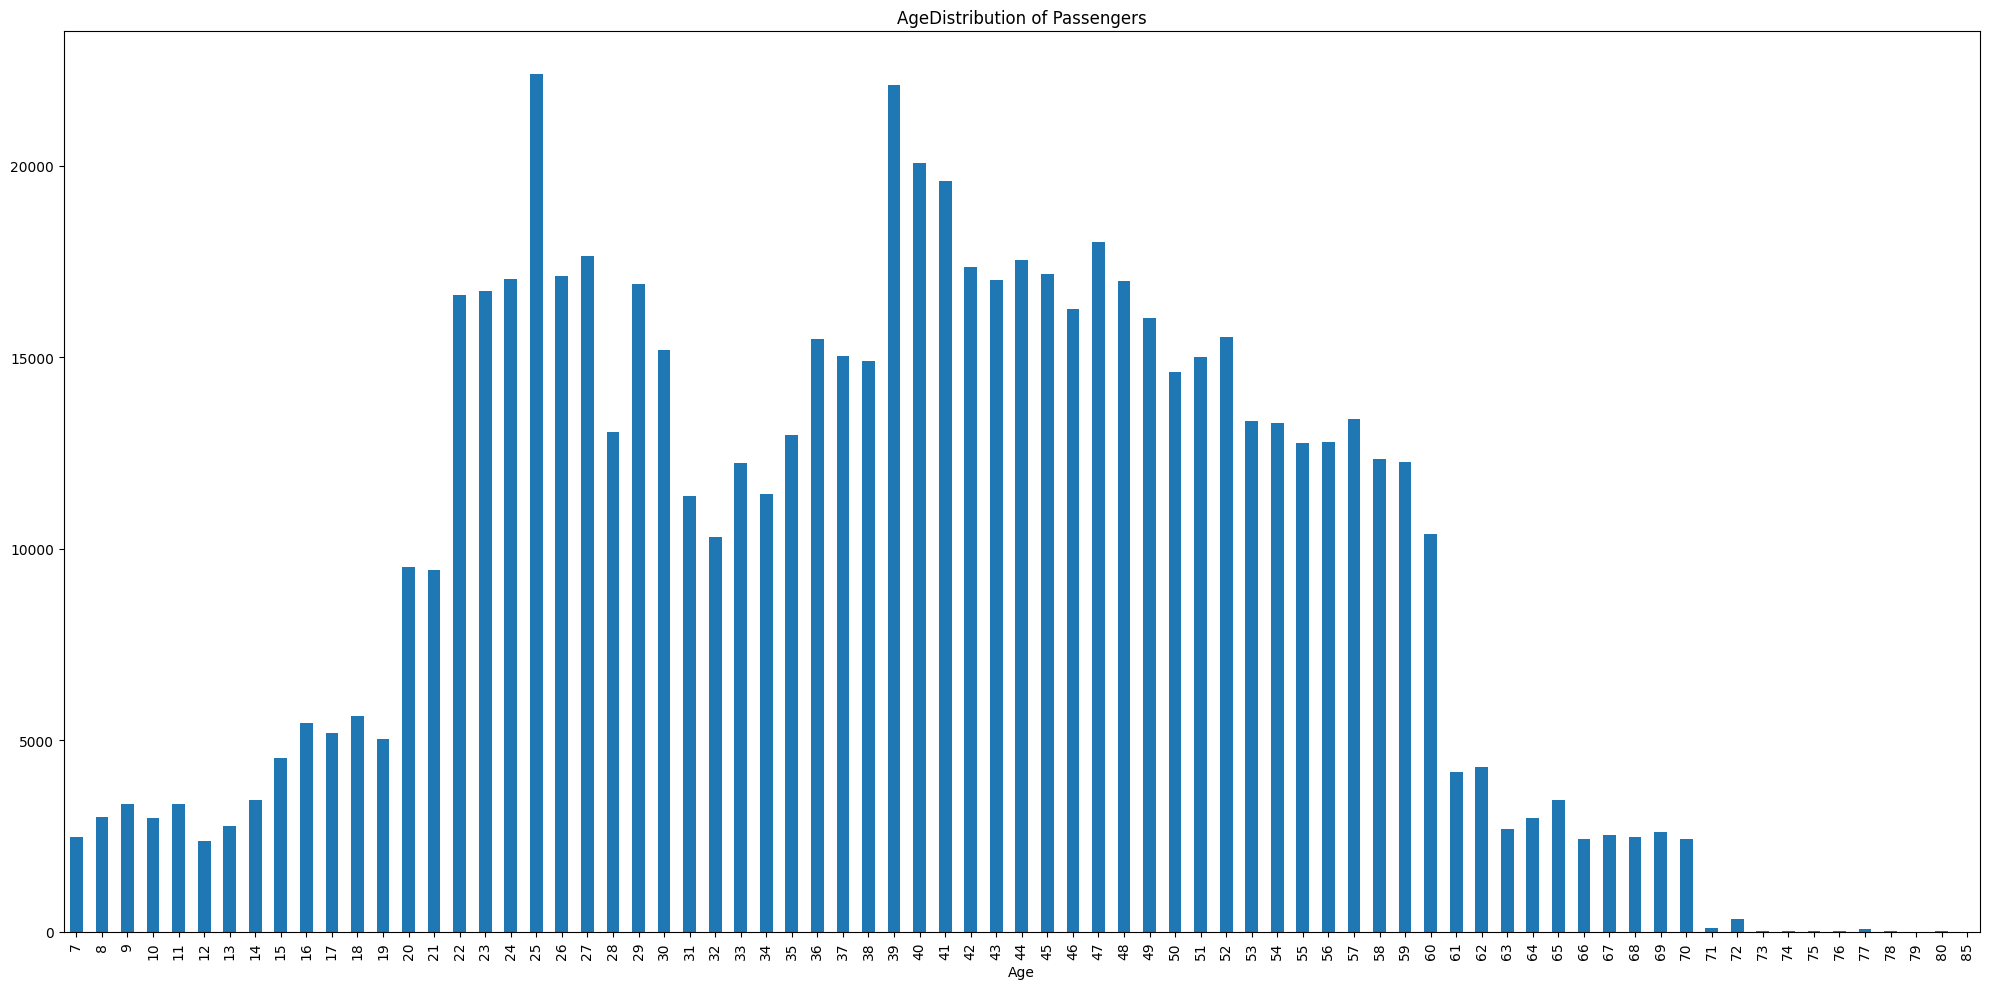

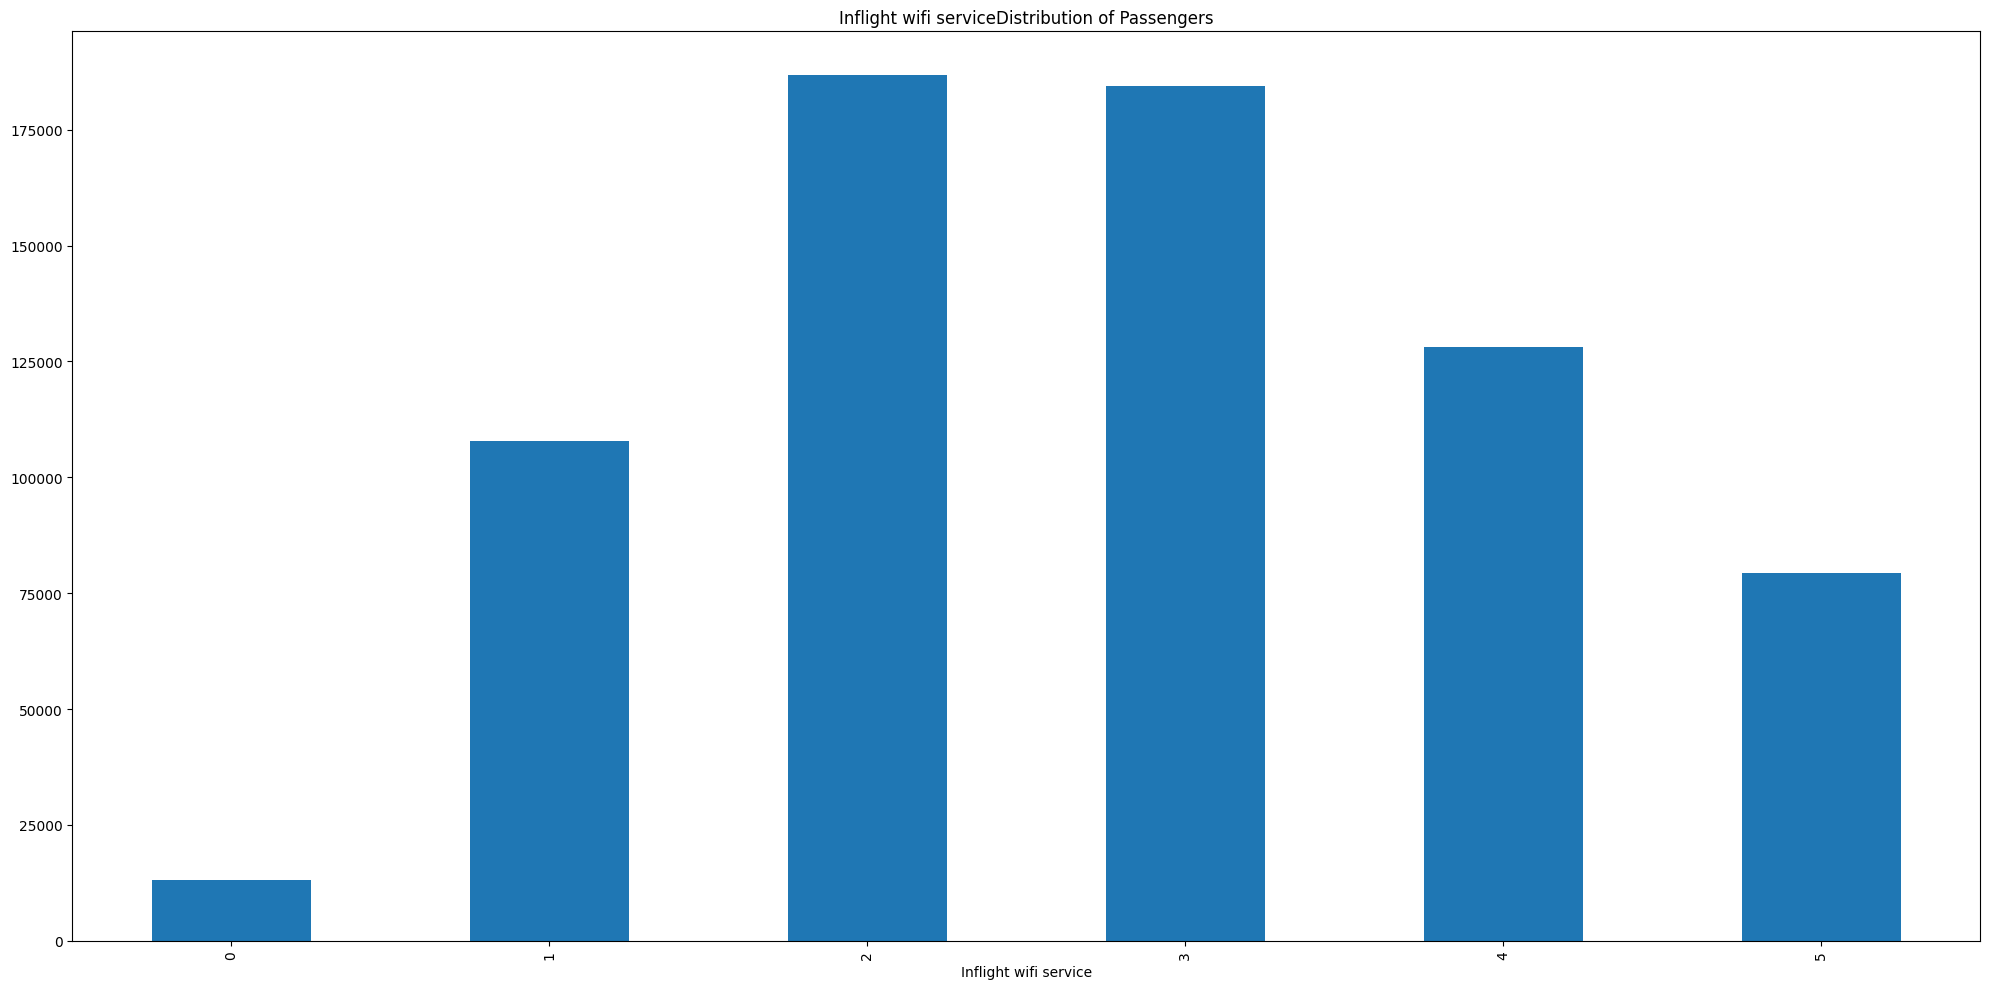

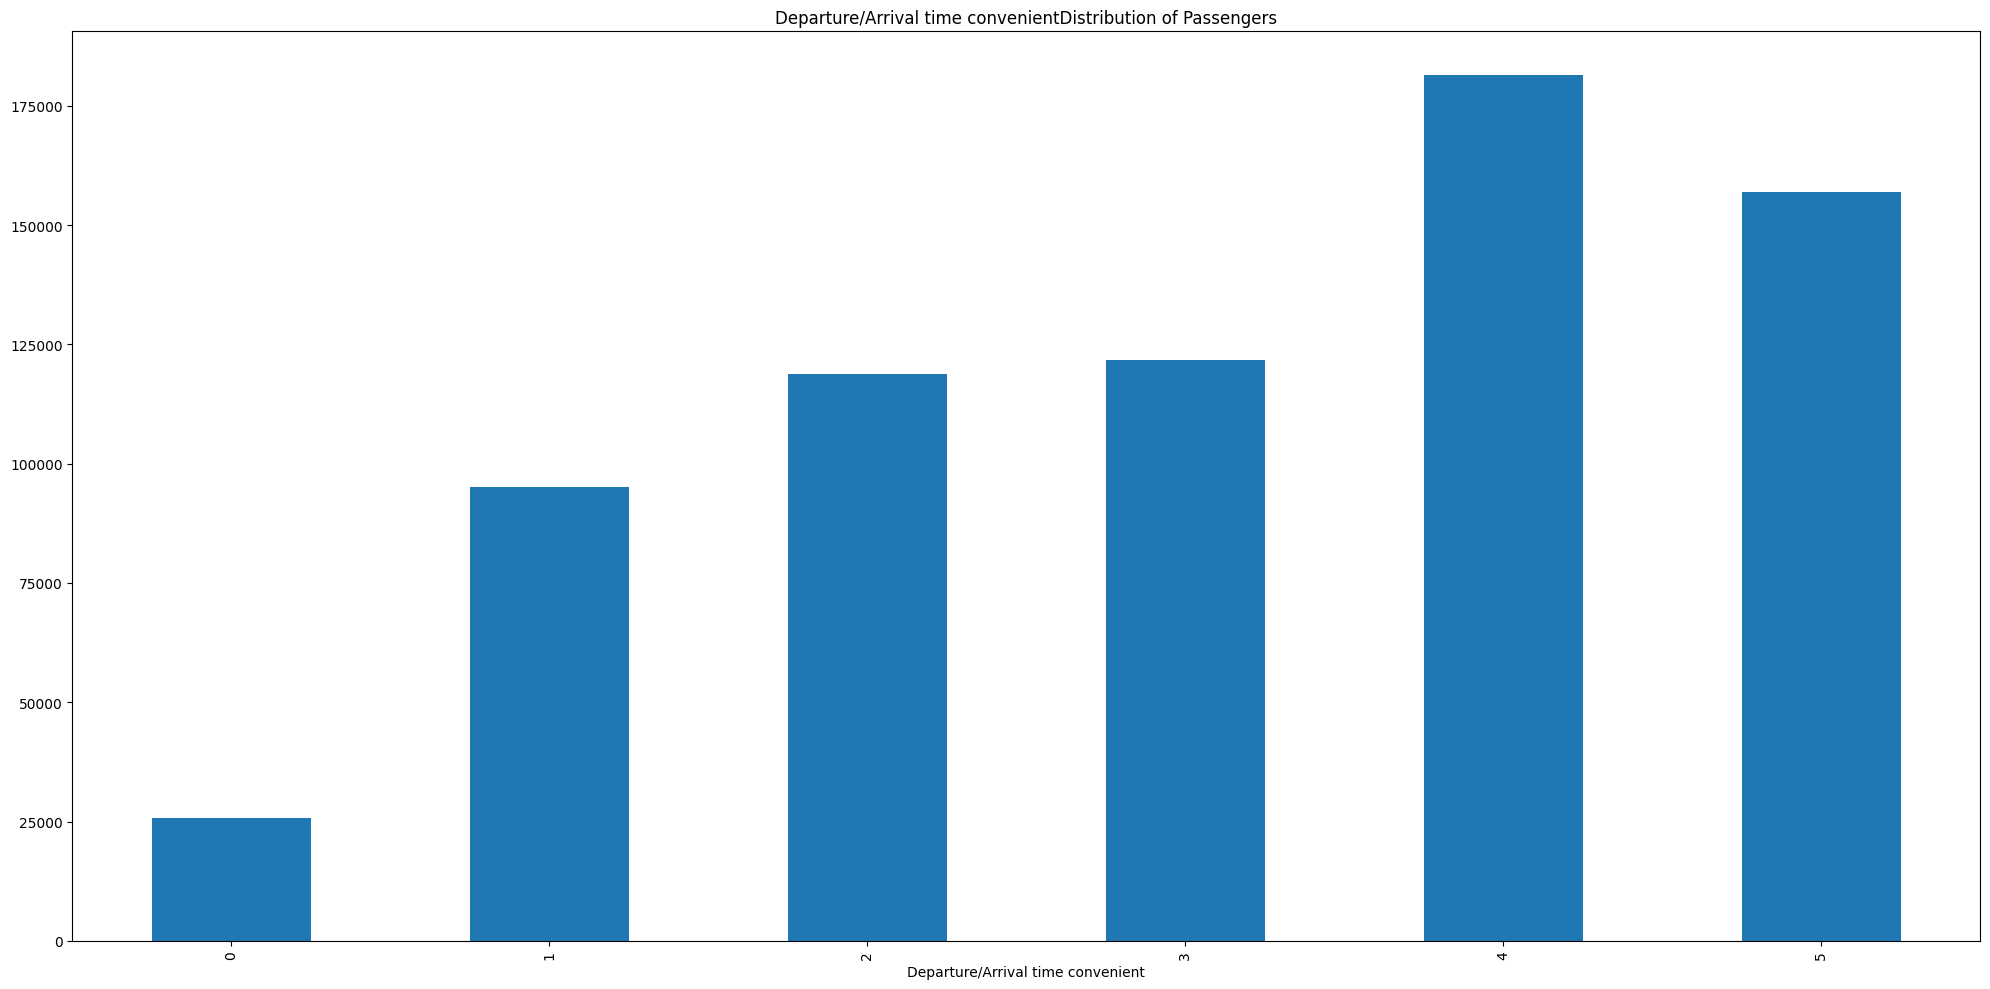

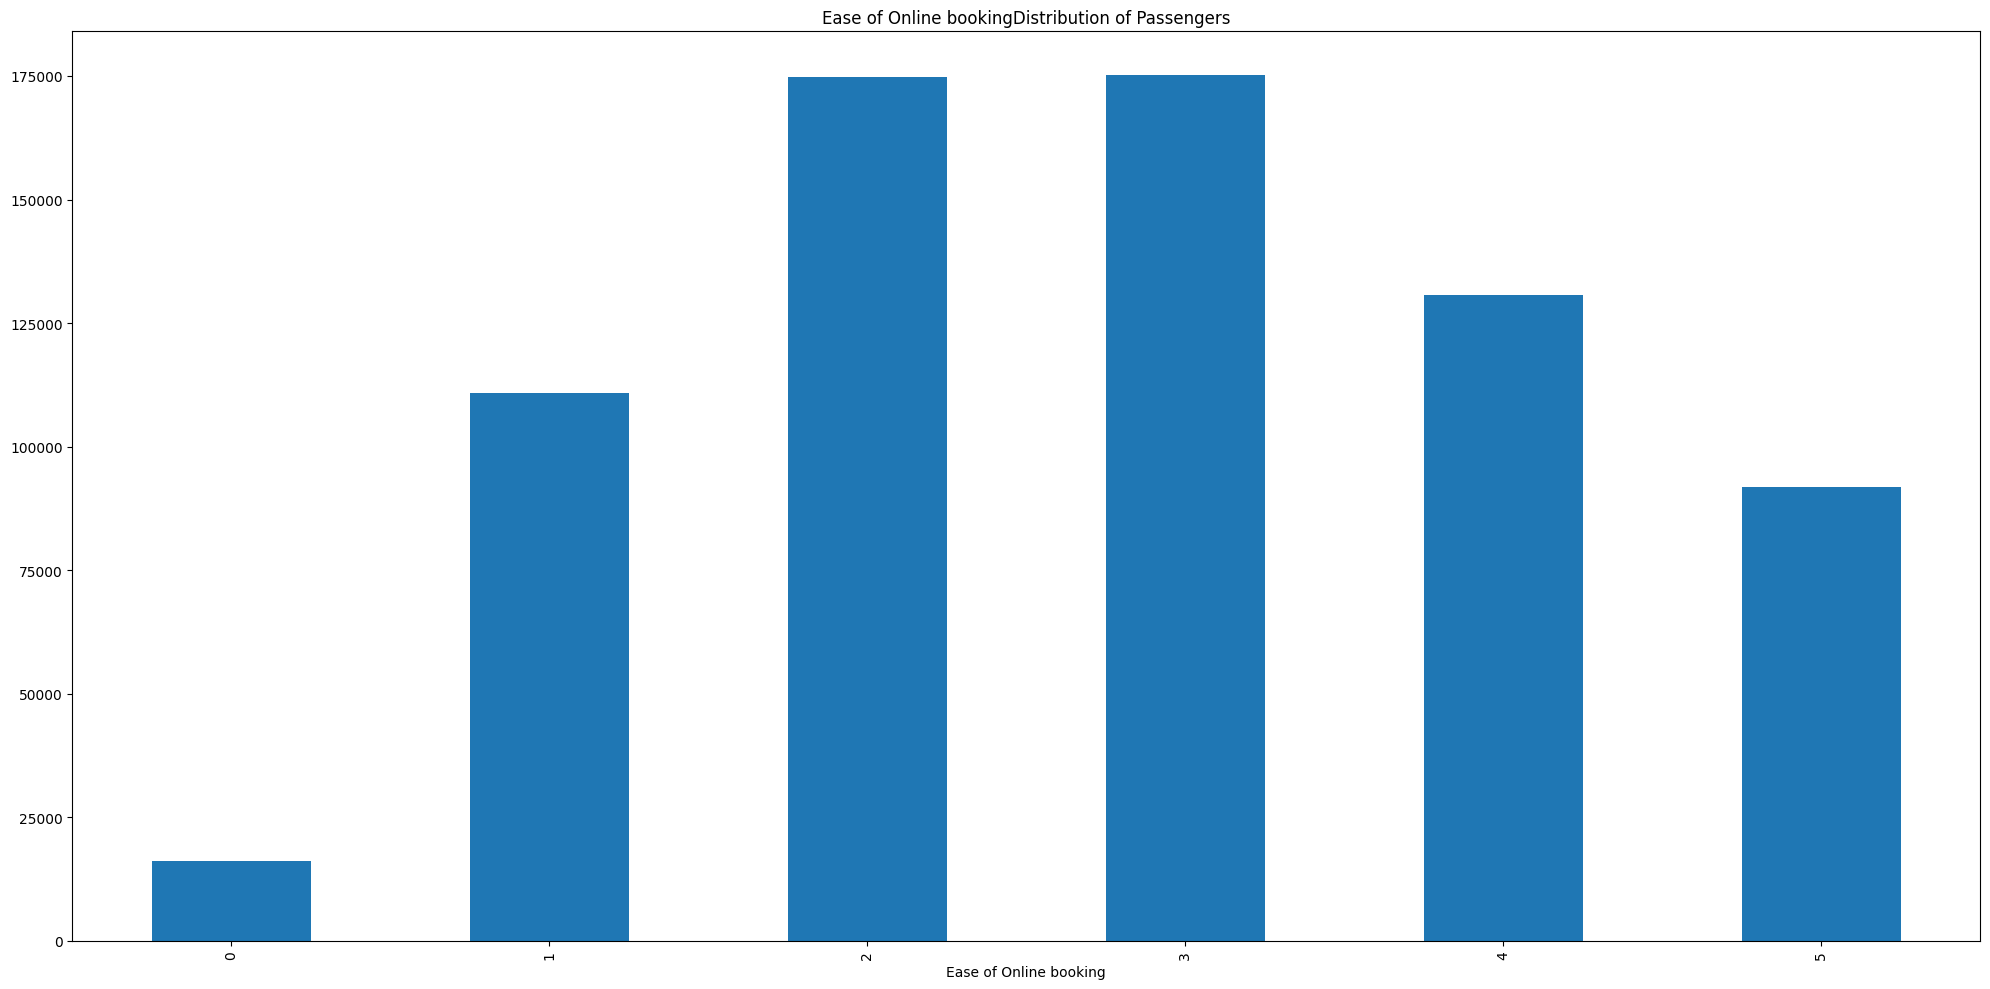

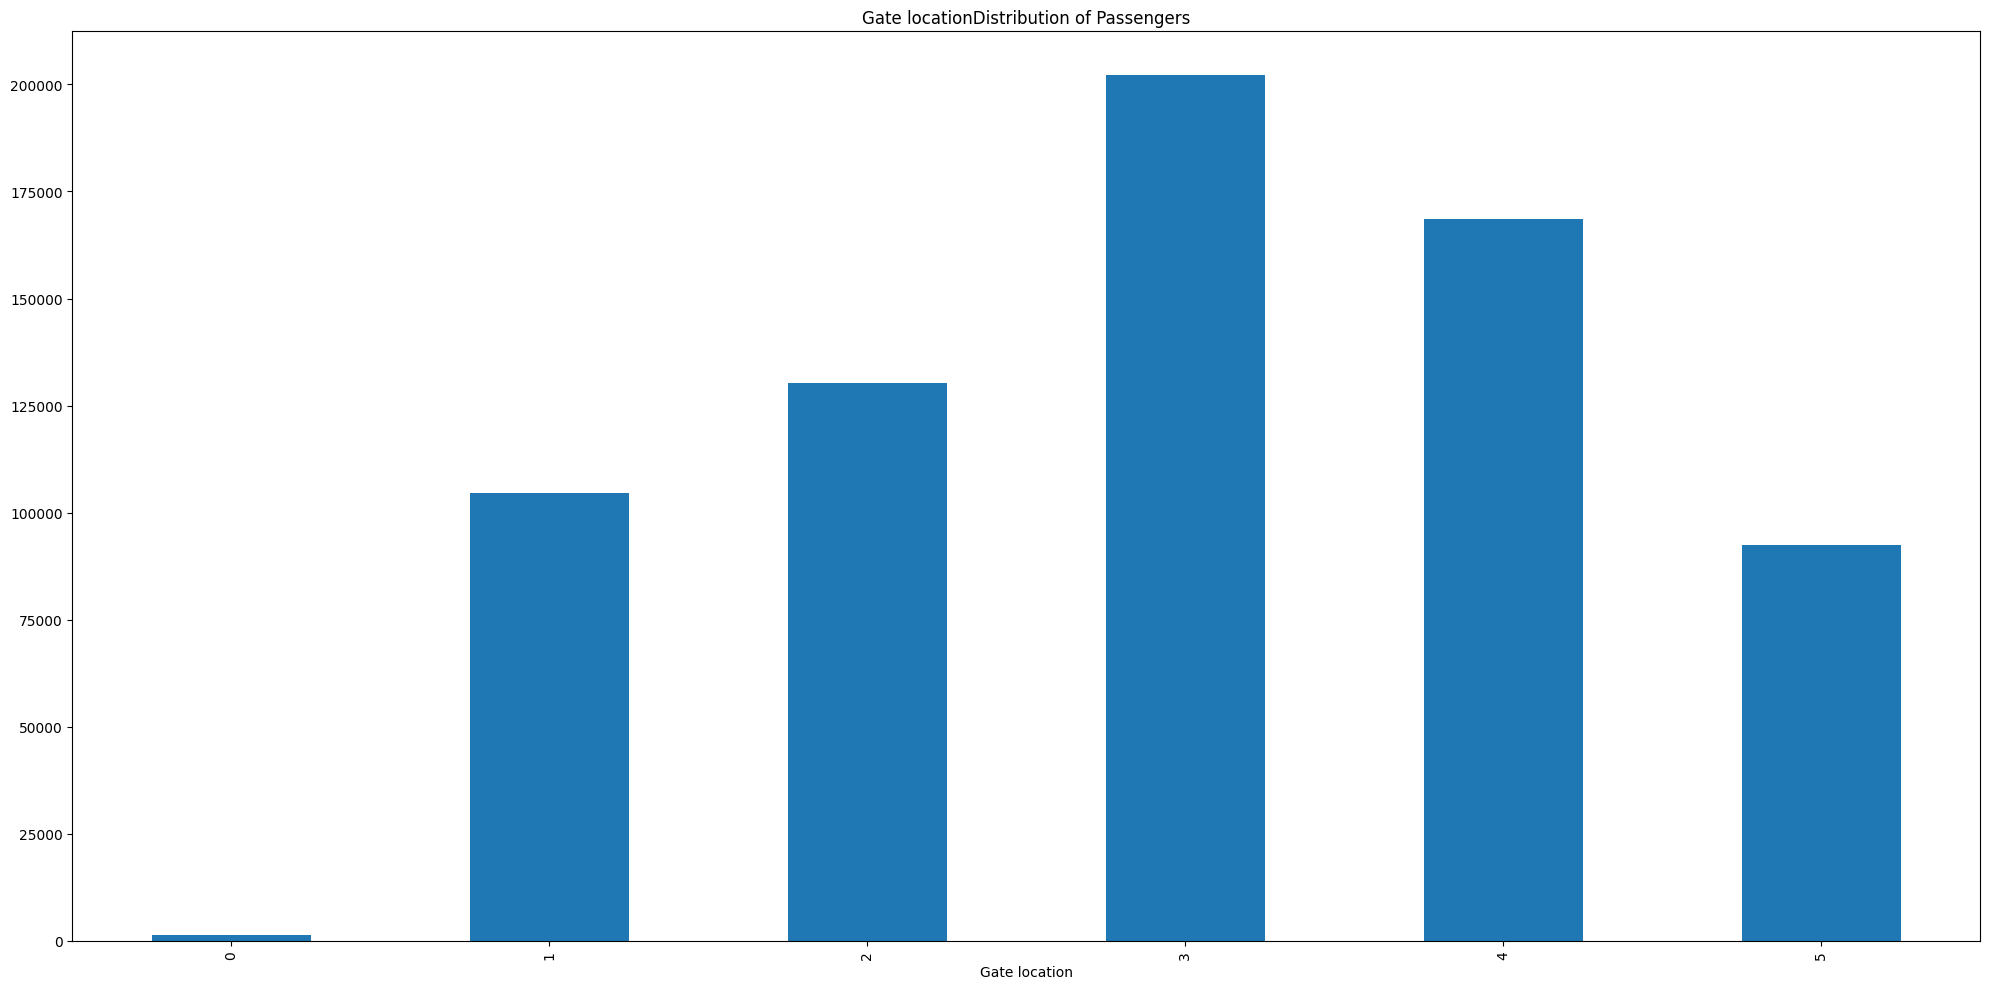

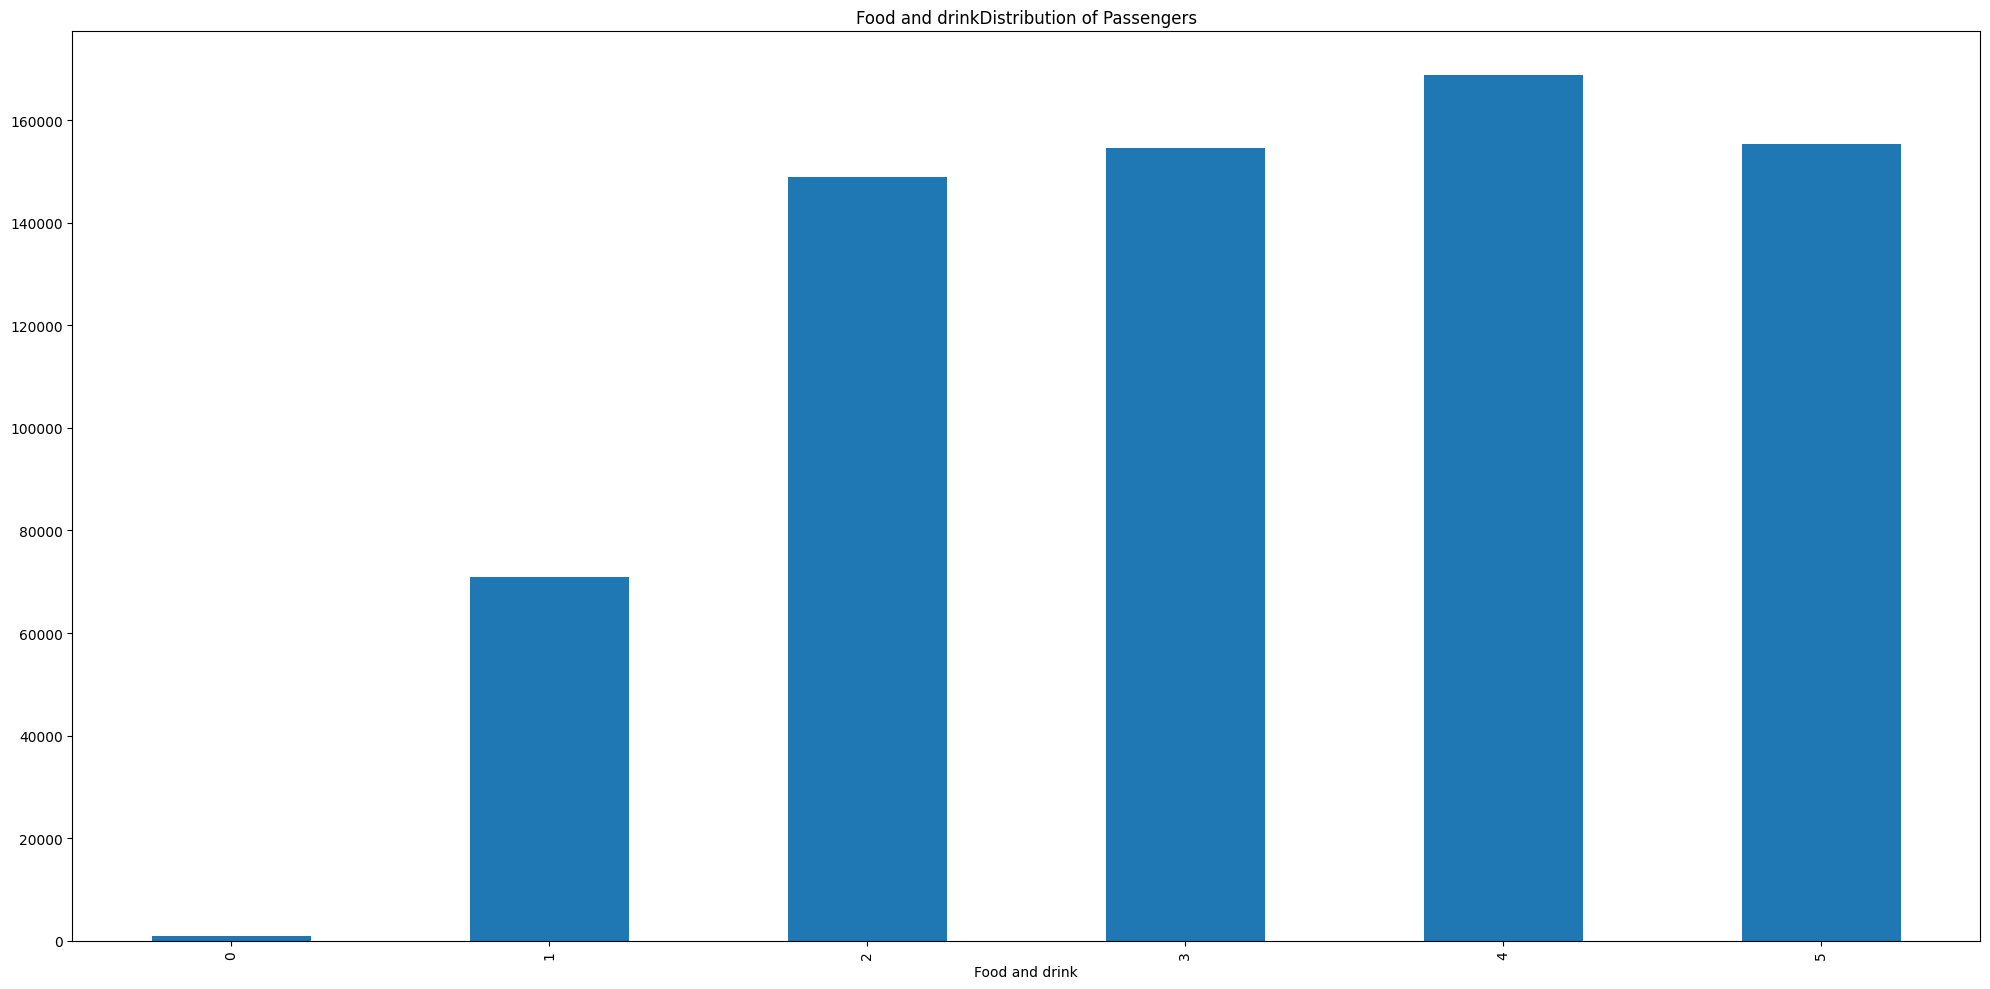

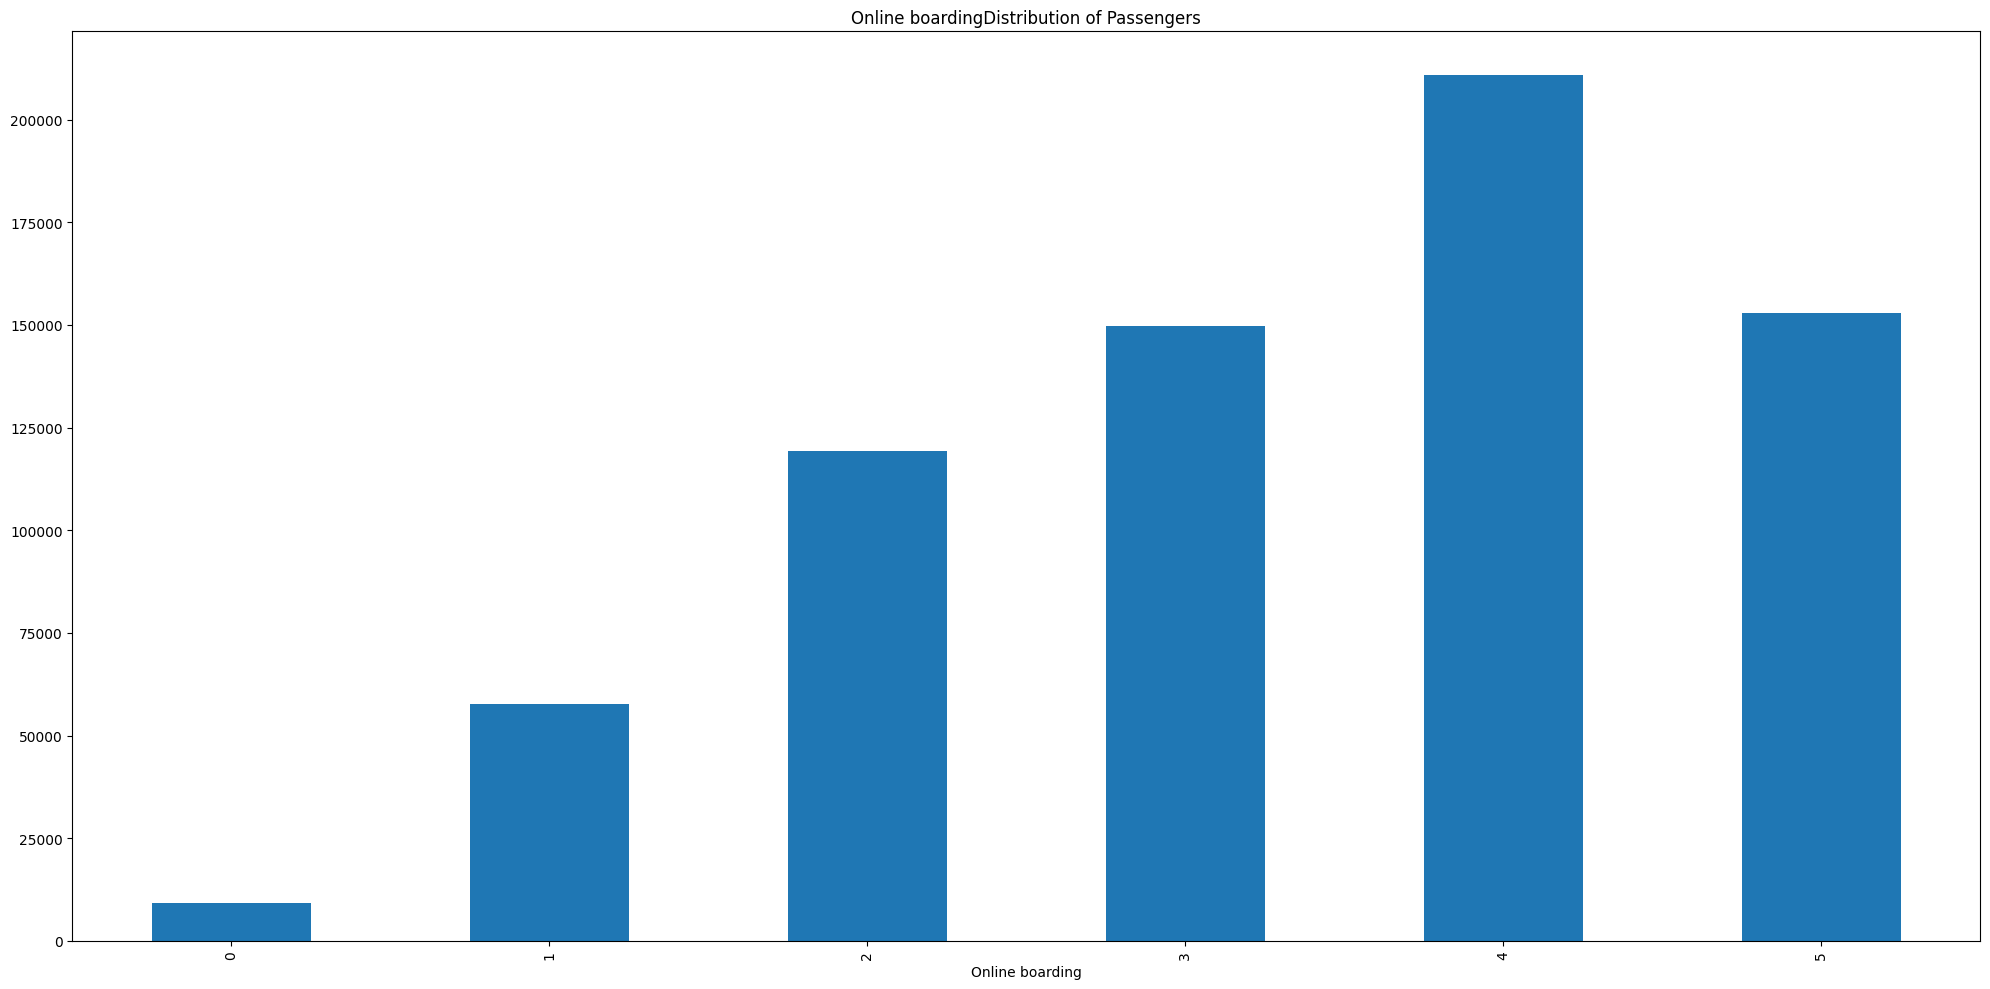

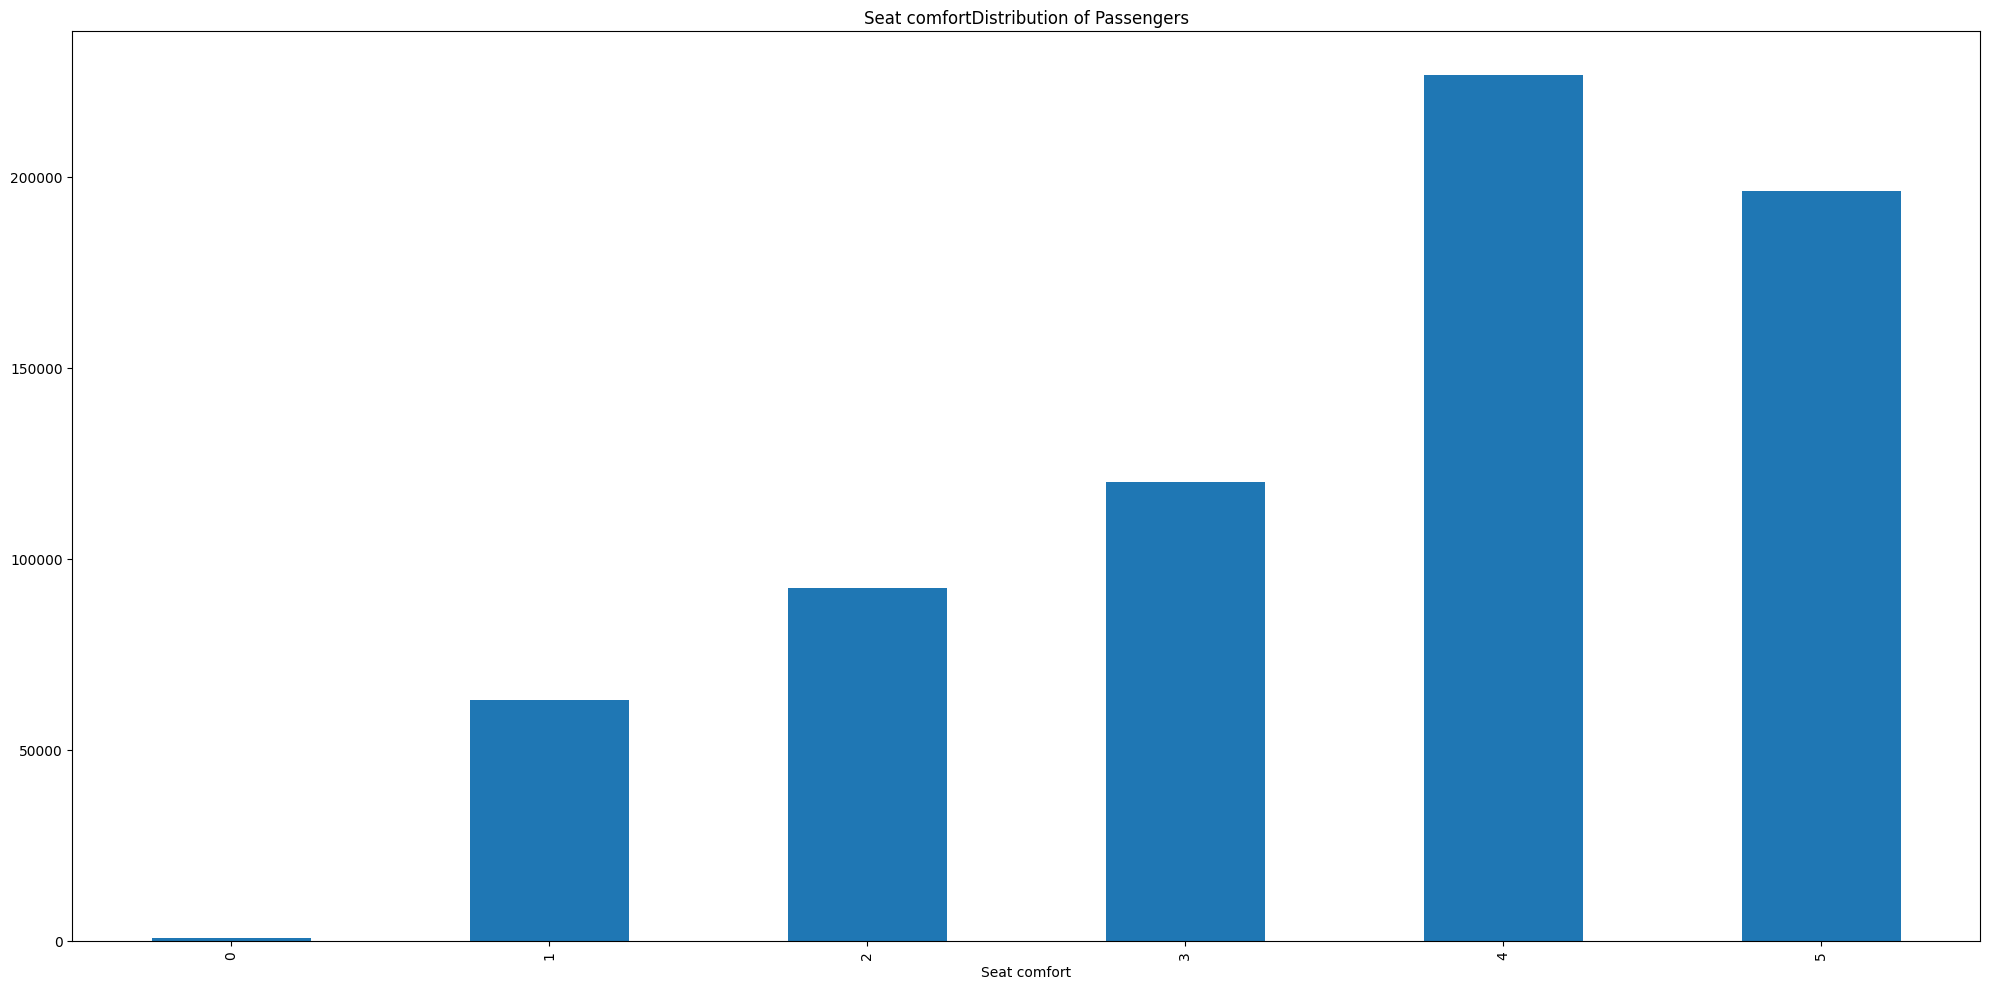

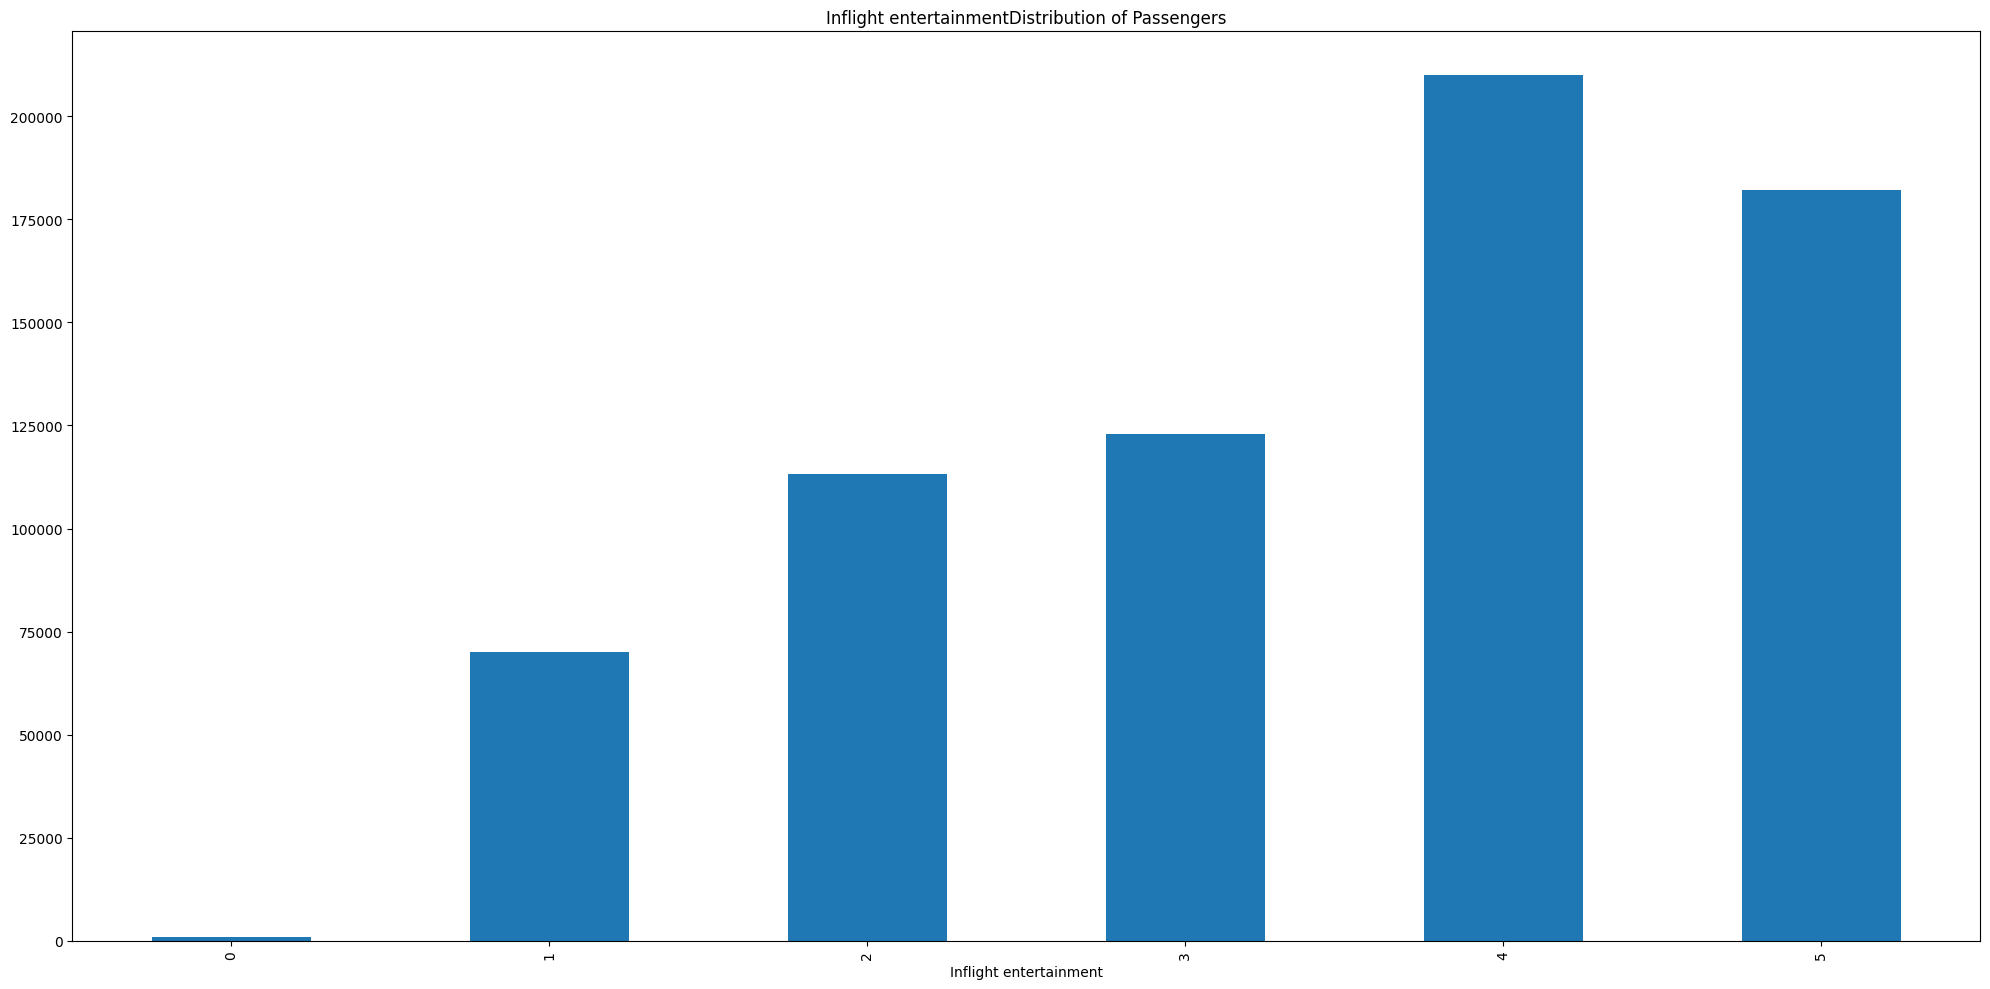

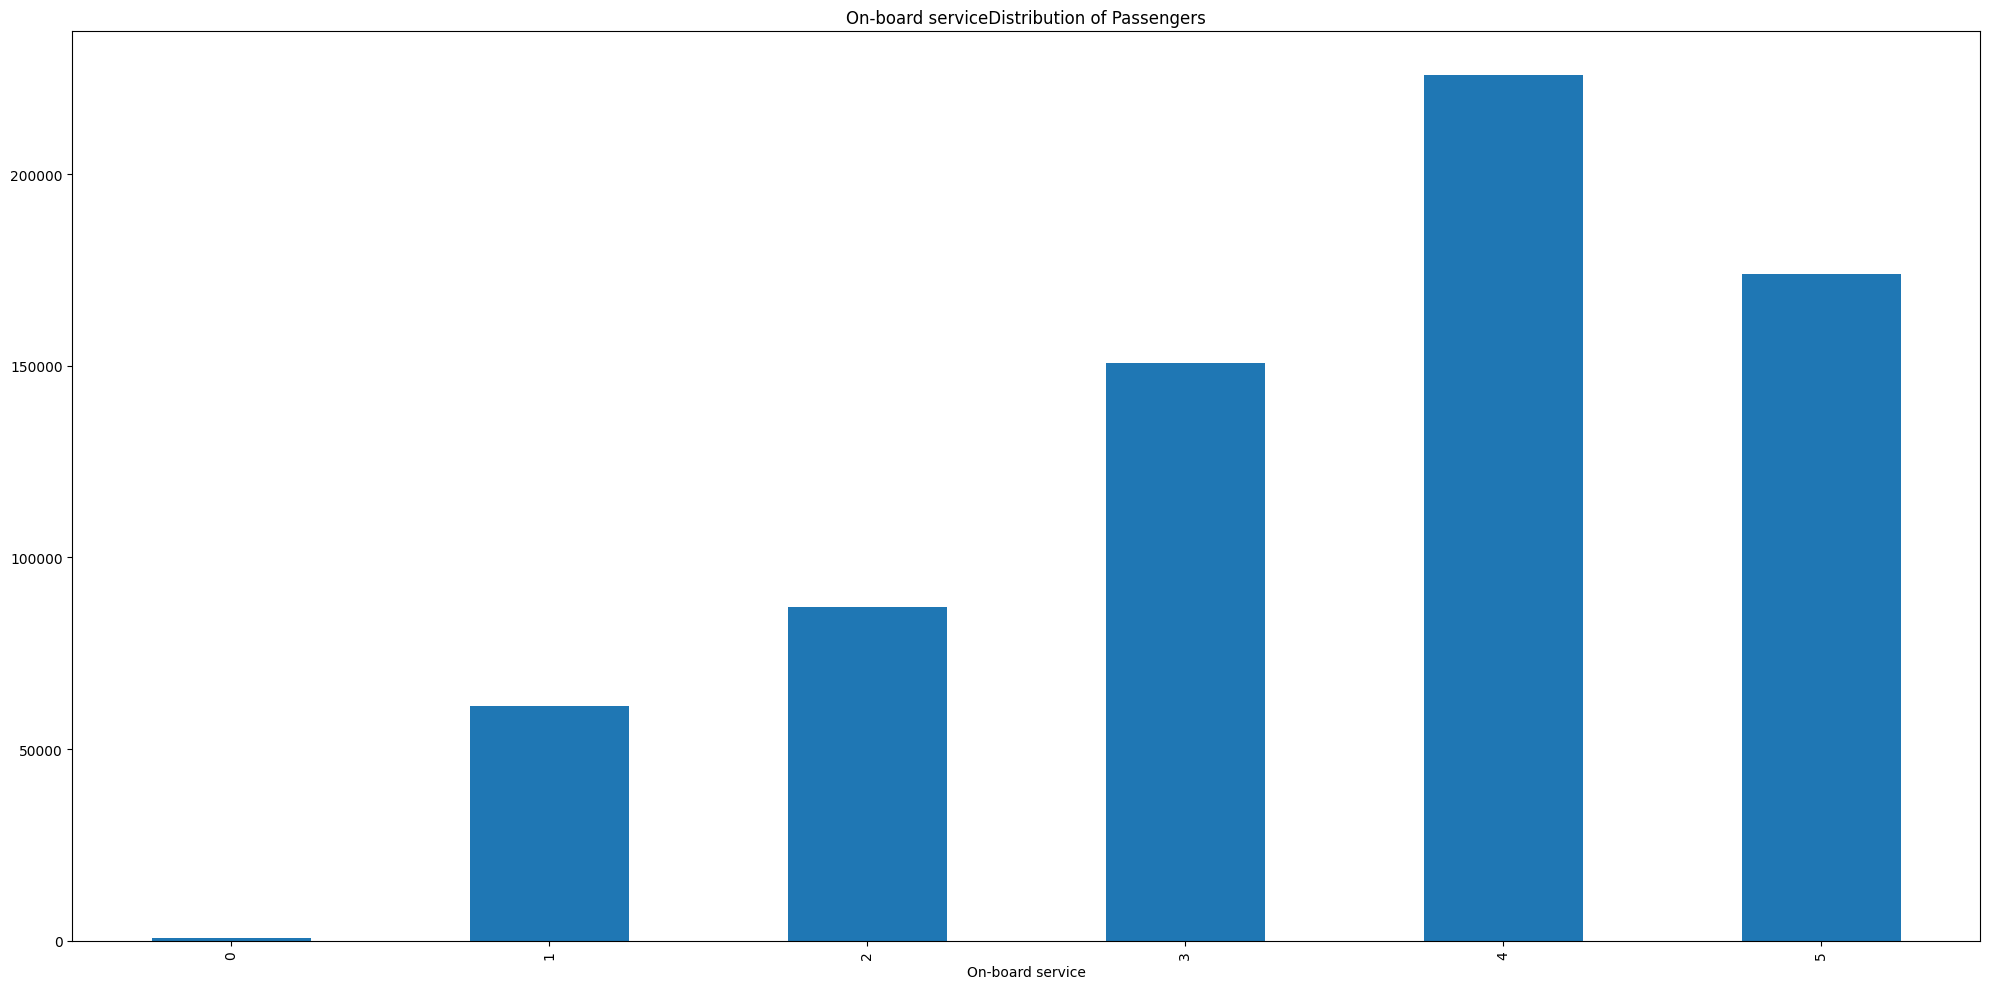

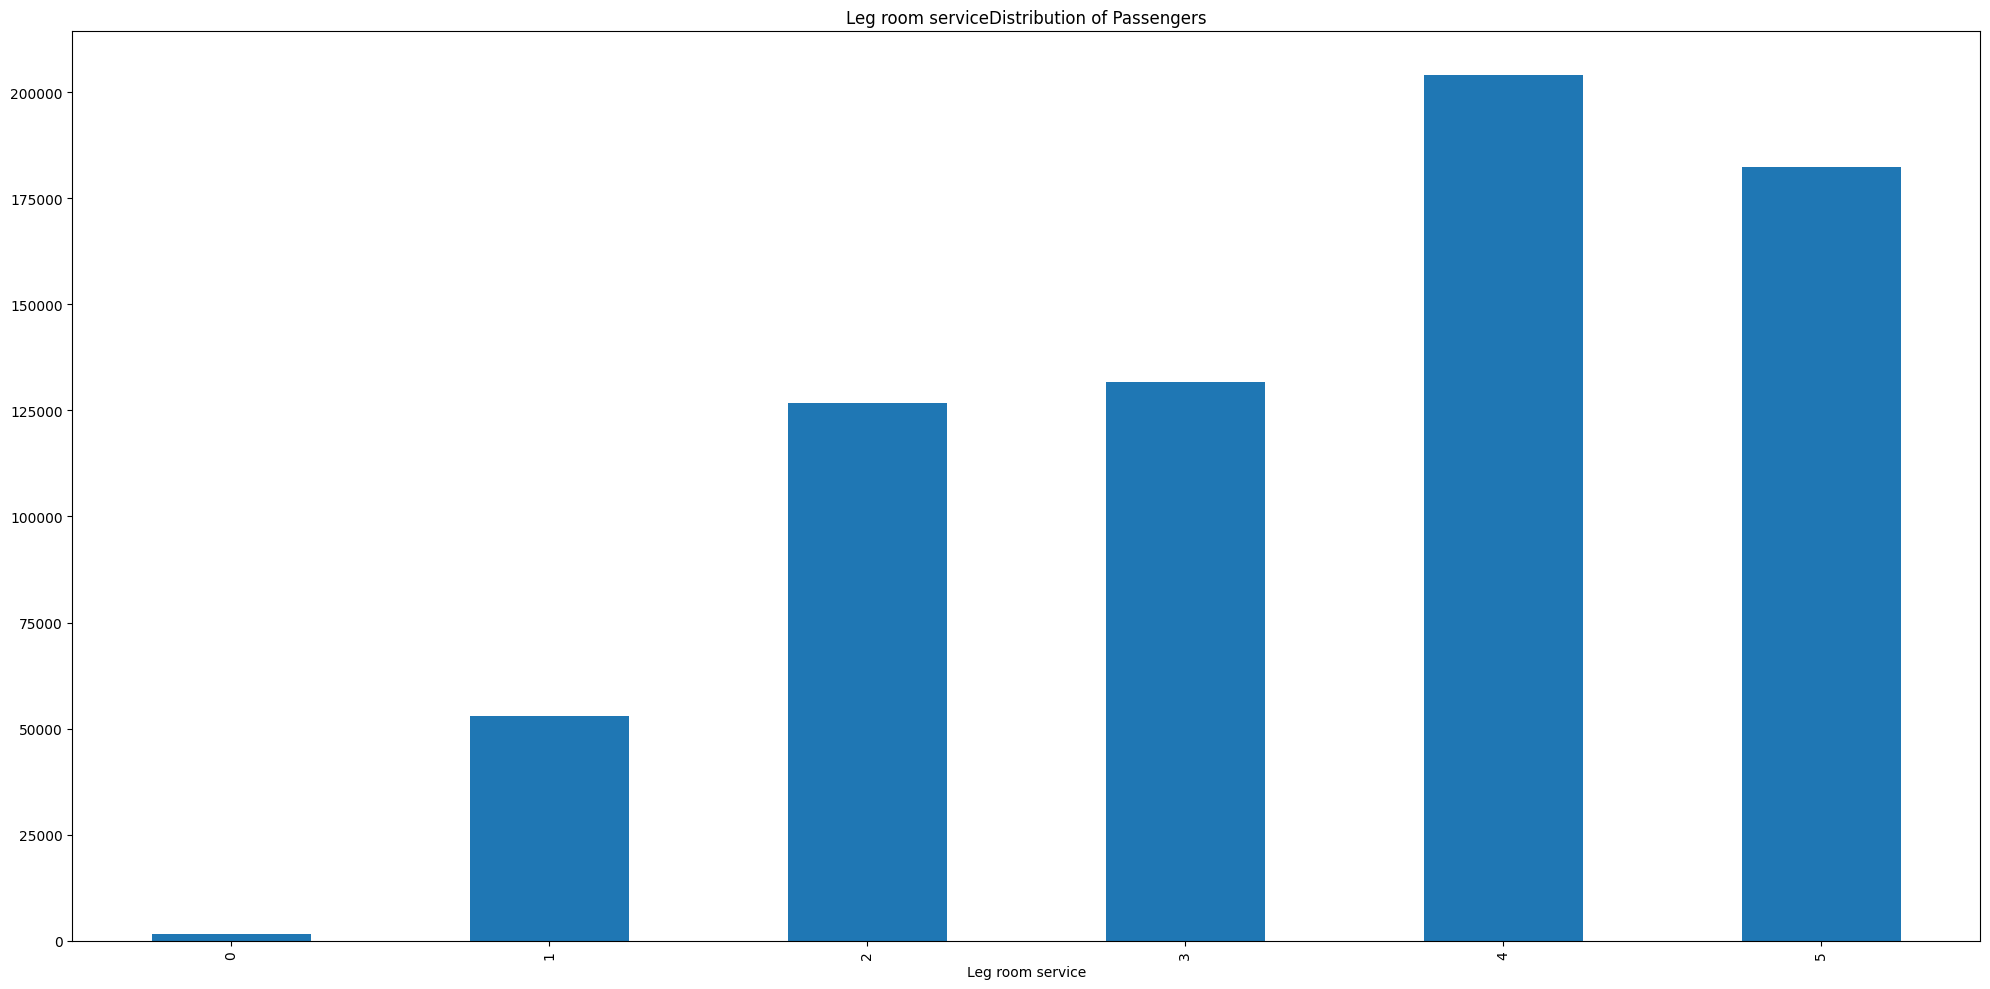

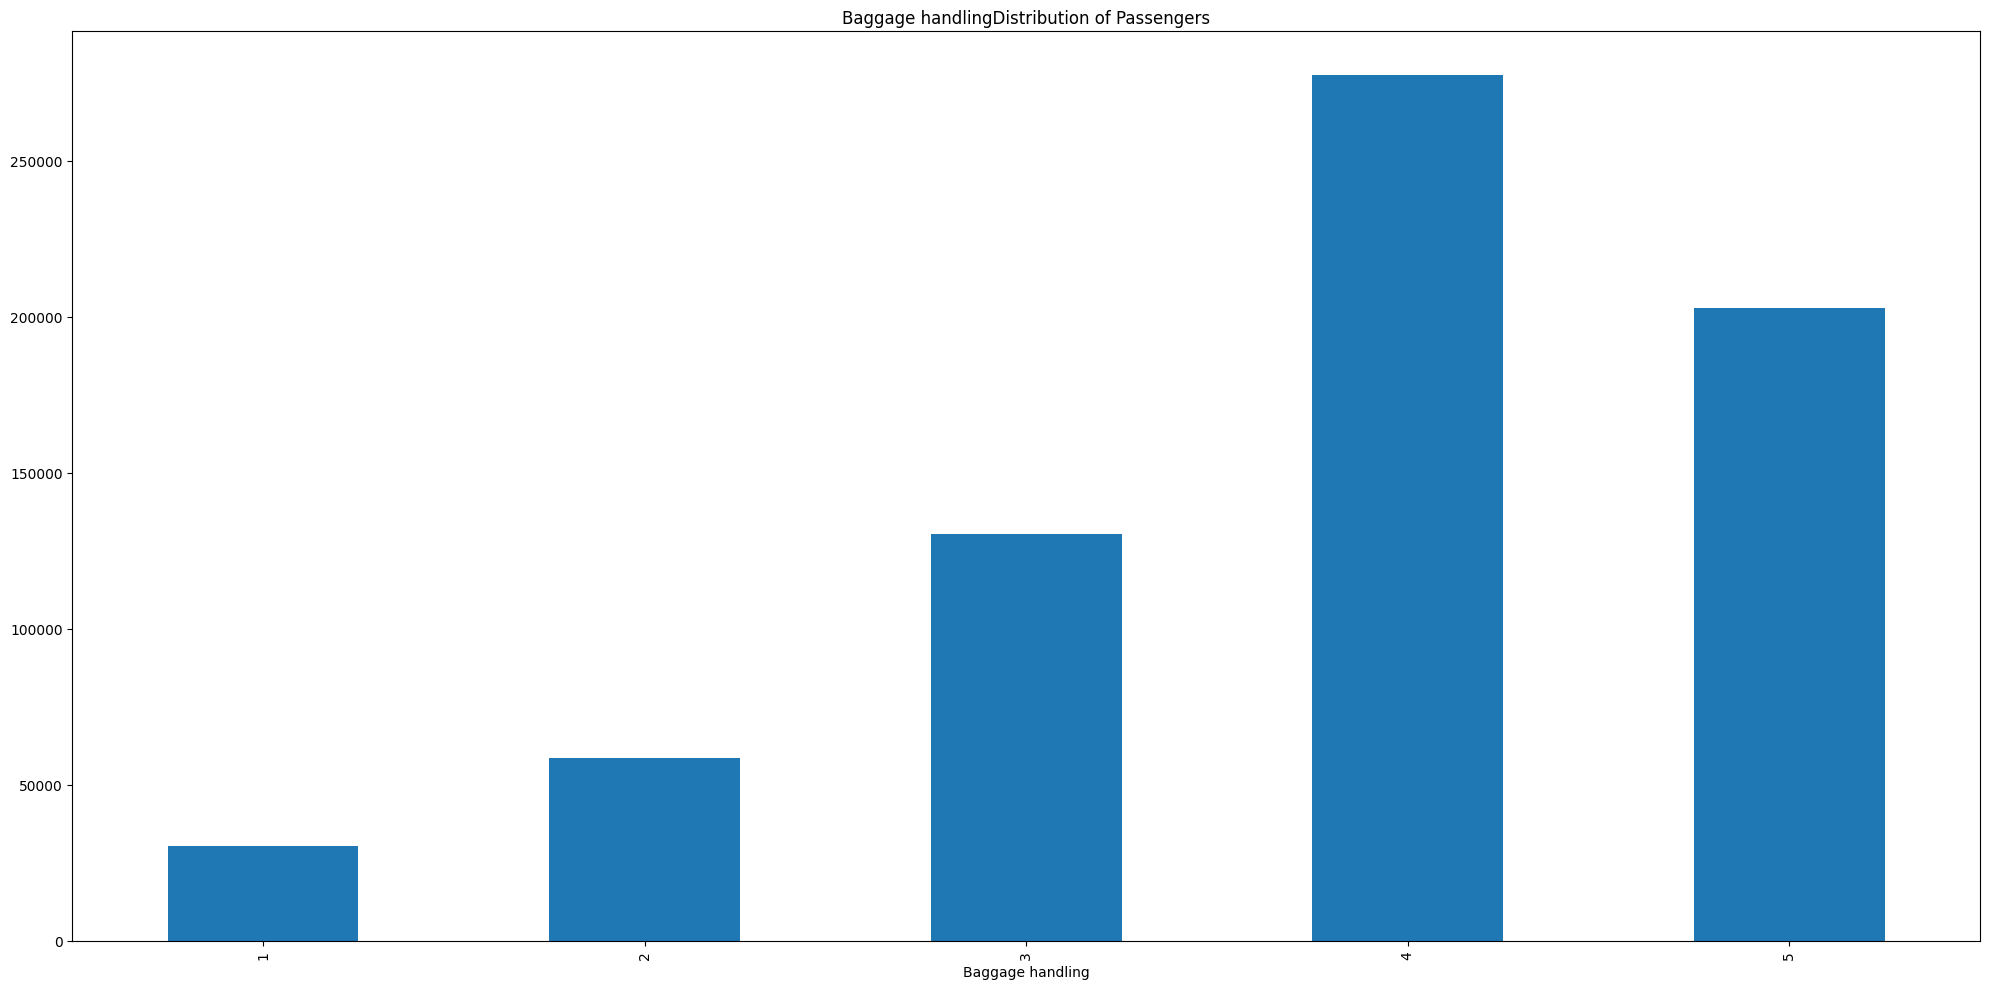

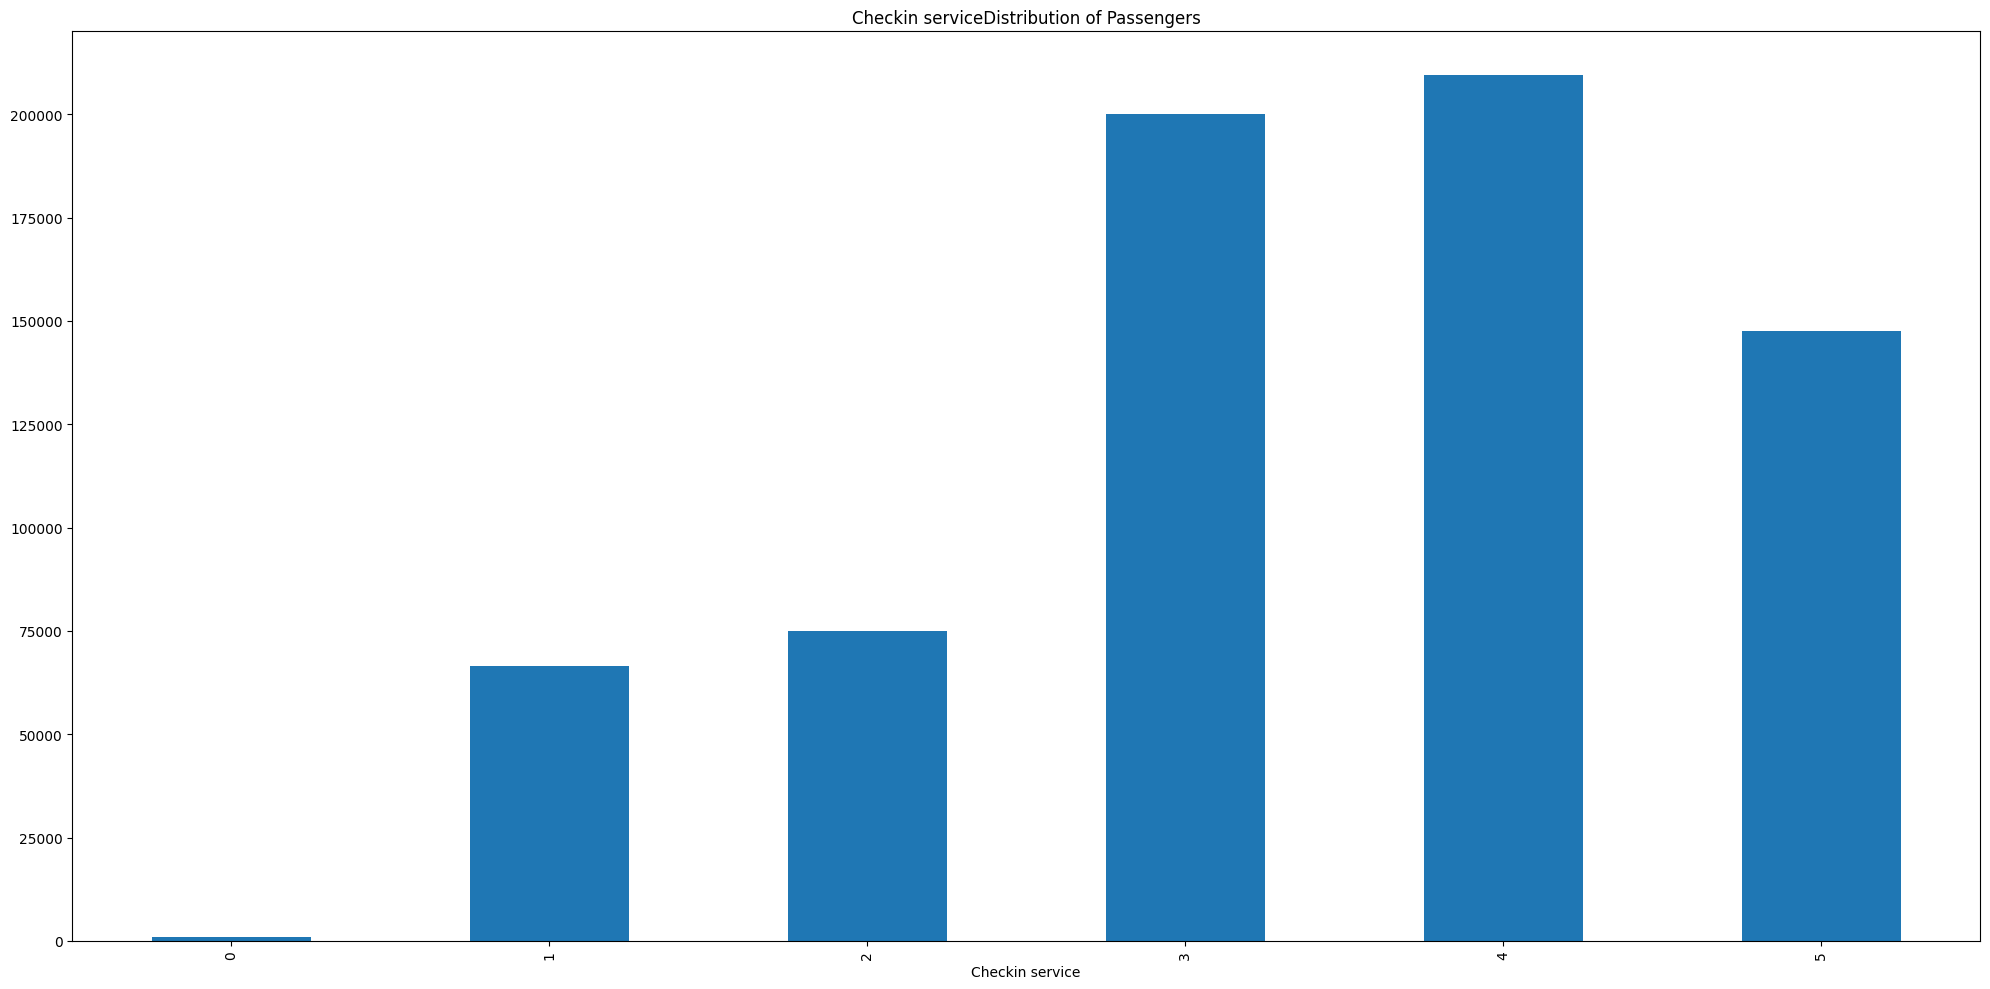

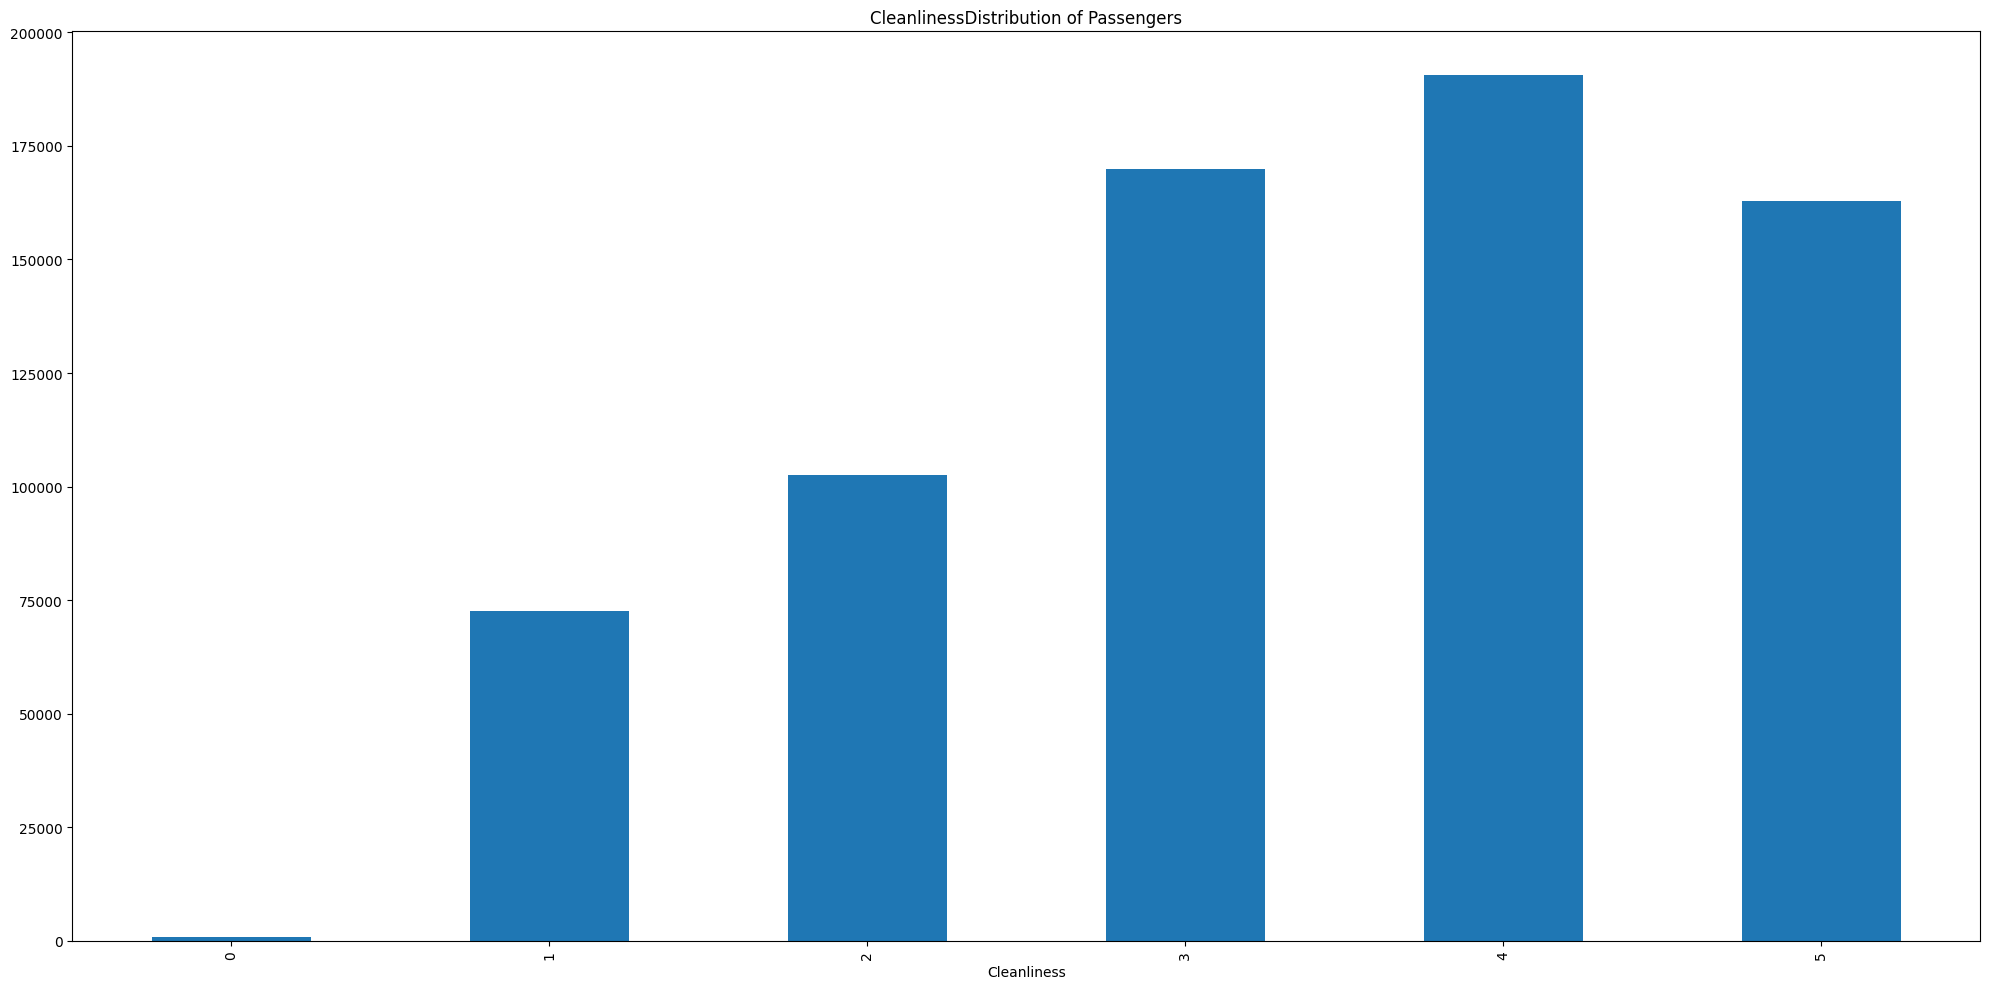

In [9]:
for _,col in data[['Age','Inflight wifi service',  'Departure/Arrival time convenient',  'Ease of Online booking'  ,'Gate location',  'Food and drink'  ,'Online boarding',  'Seat comfort',  'Inflight entertainment',  'On-board service',  'Leg room service',  'Baggage handling',  'Checkin service',  'Cleanliness']].items():
    plt.figure(figsize=(20,10))
    col.value_counts().sort_index().plot(kind='bar')
    plt.title(col.name+'Distribution of Passengers')
    plt.tight_layout()
    plt.show()

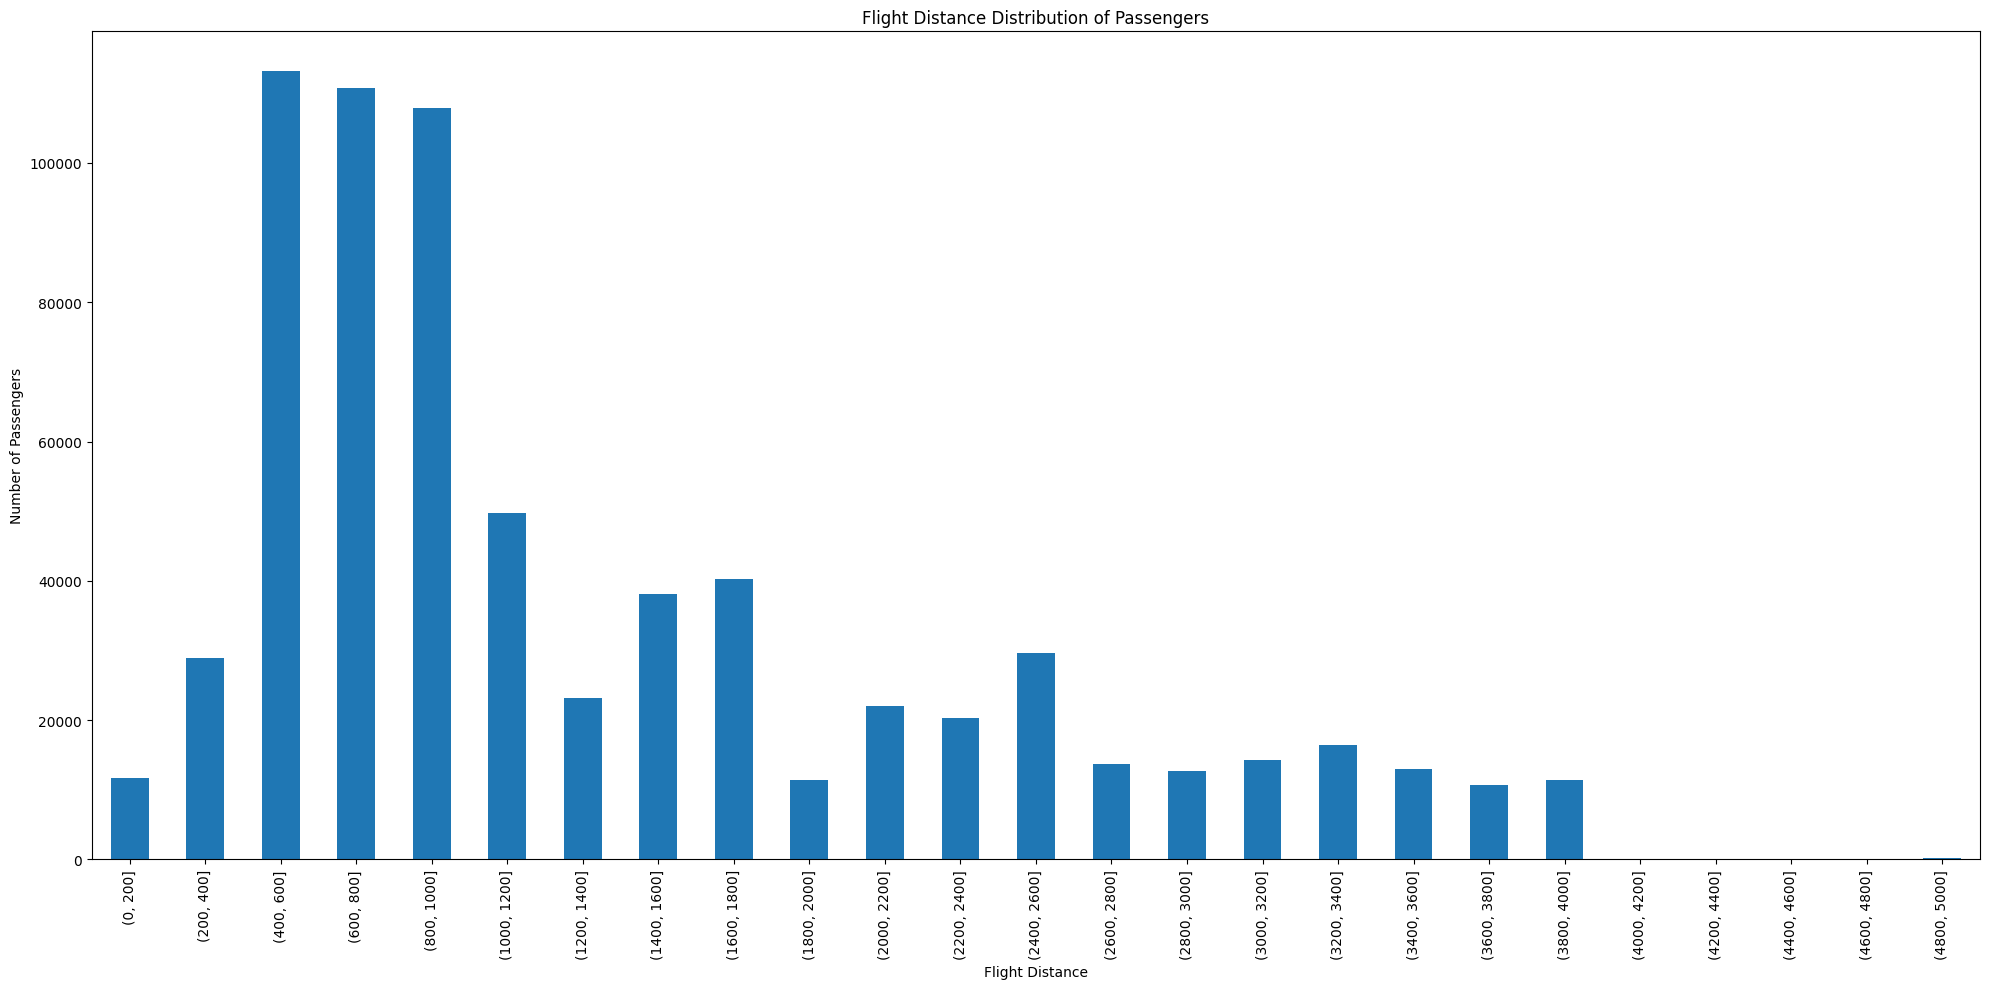

In [10]:
plt.figure(figsize=(20,10))
bins=np.arange(0,5200,200)
flight_distance_distribution=data['Flight Distance']
pd.cut(flight_distance_distribution,bins=bins).value_counts().sort_index().plot(kind='bar')
plt.title('Flight Distance Distribution of Passengers')
plt.xlabel('Flight Distance')
plt.ylabel('Number of Passengers')
plt.tight_layout()
plt.show()

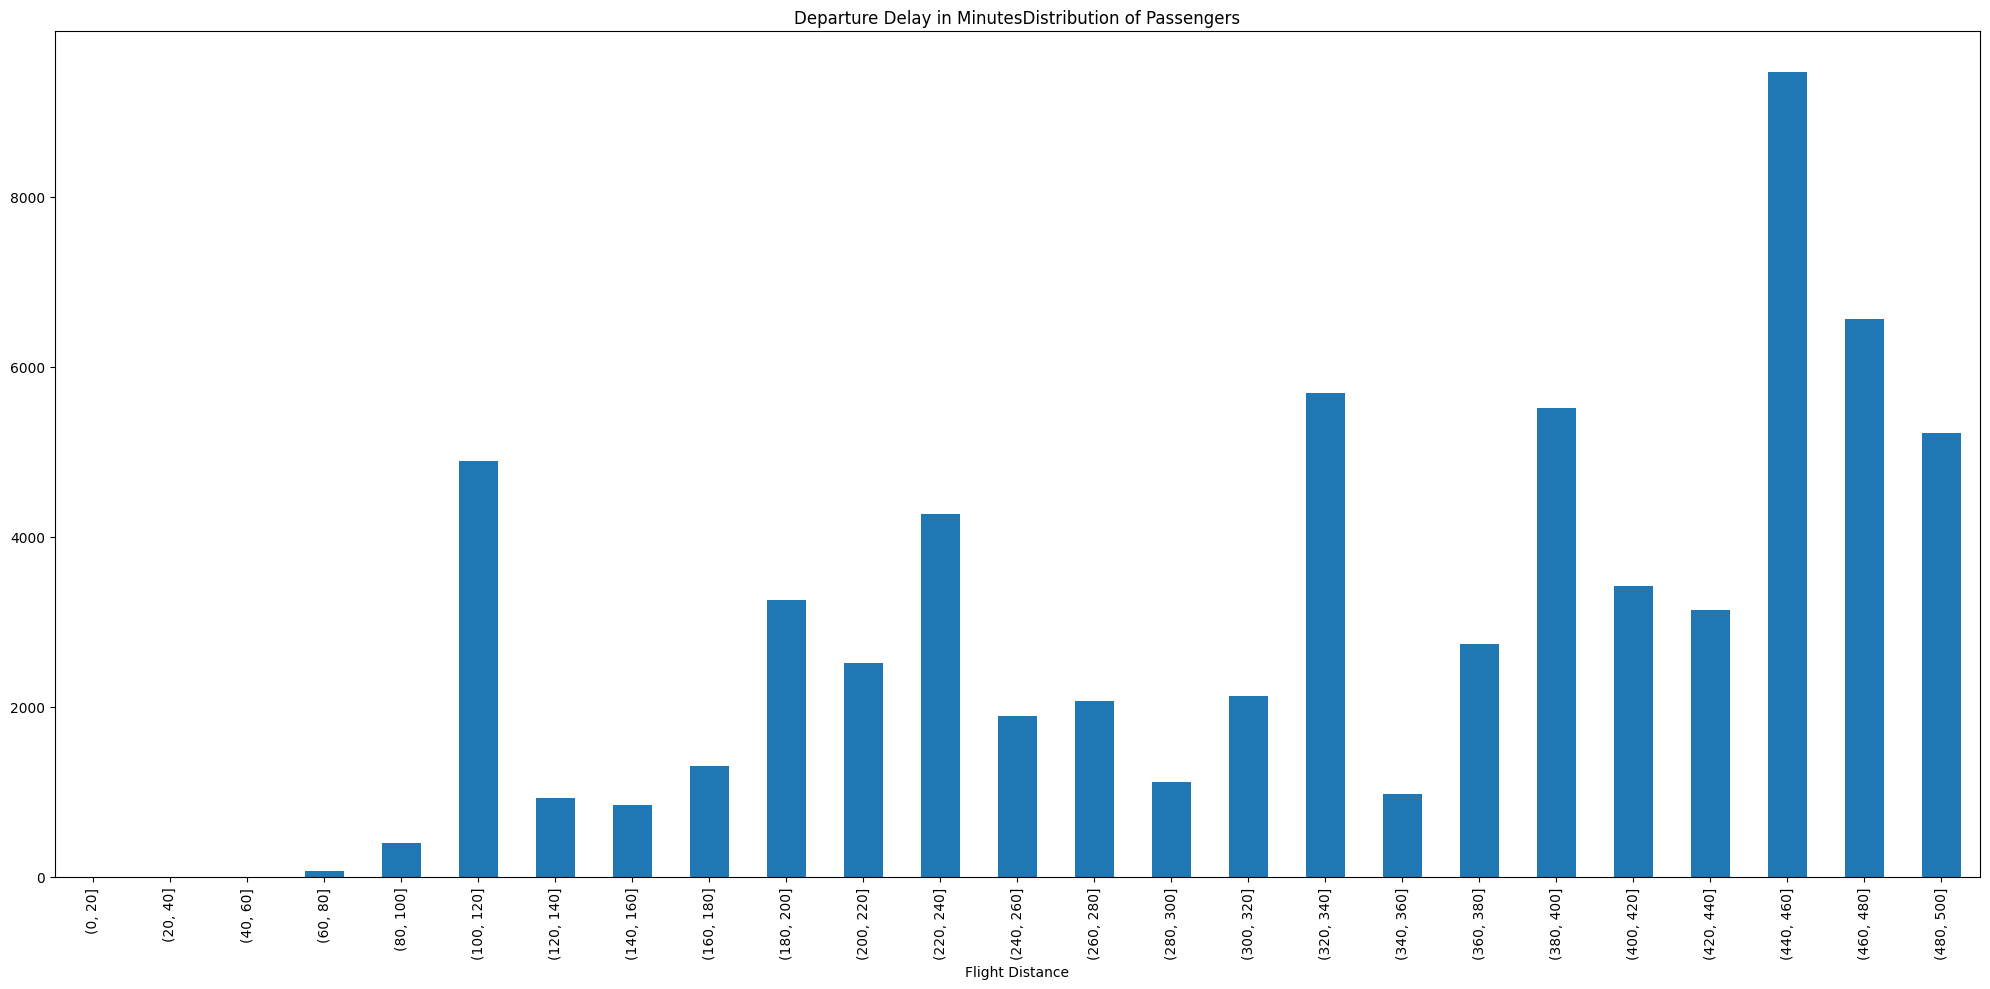

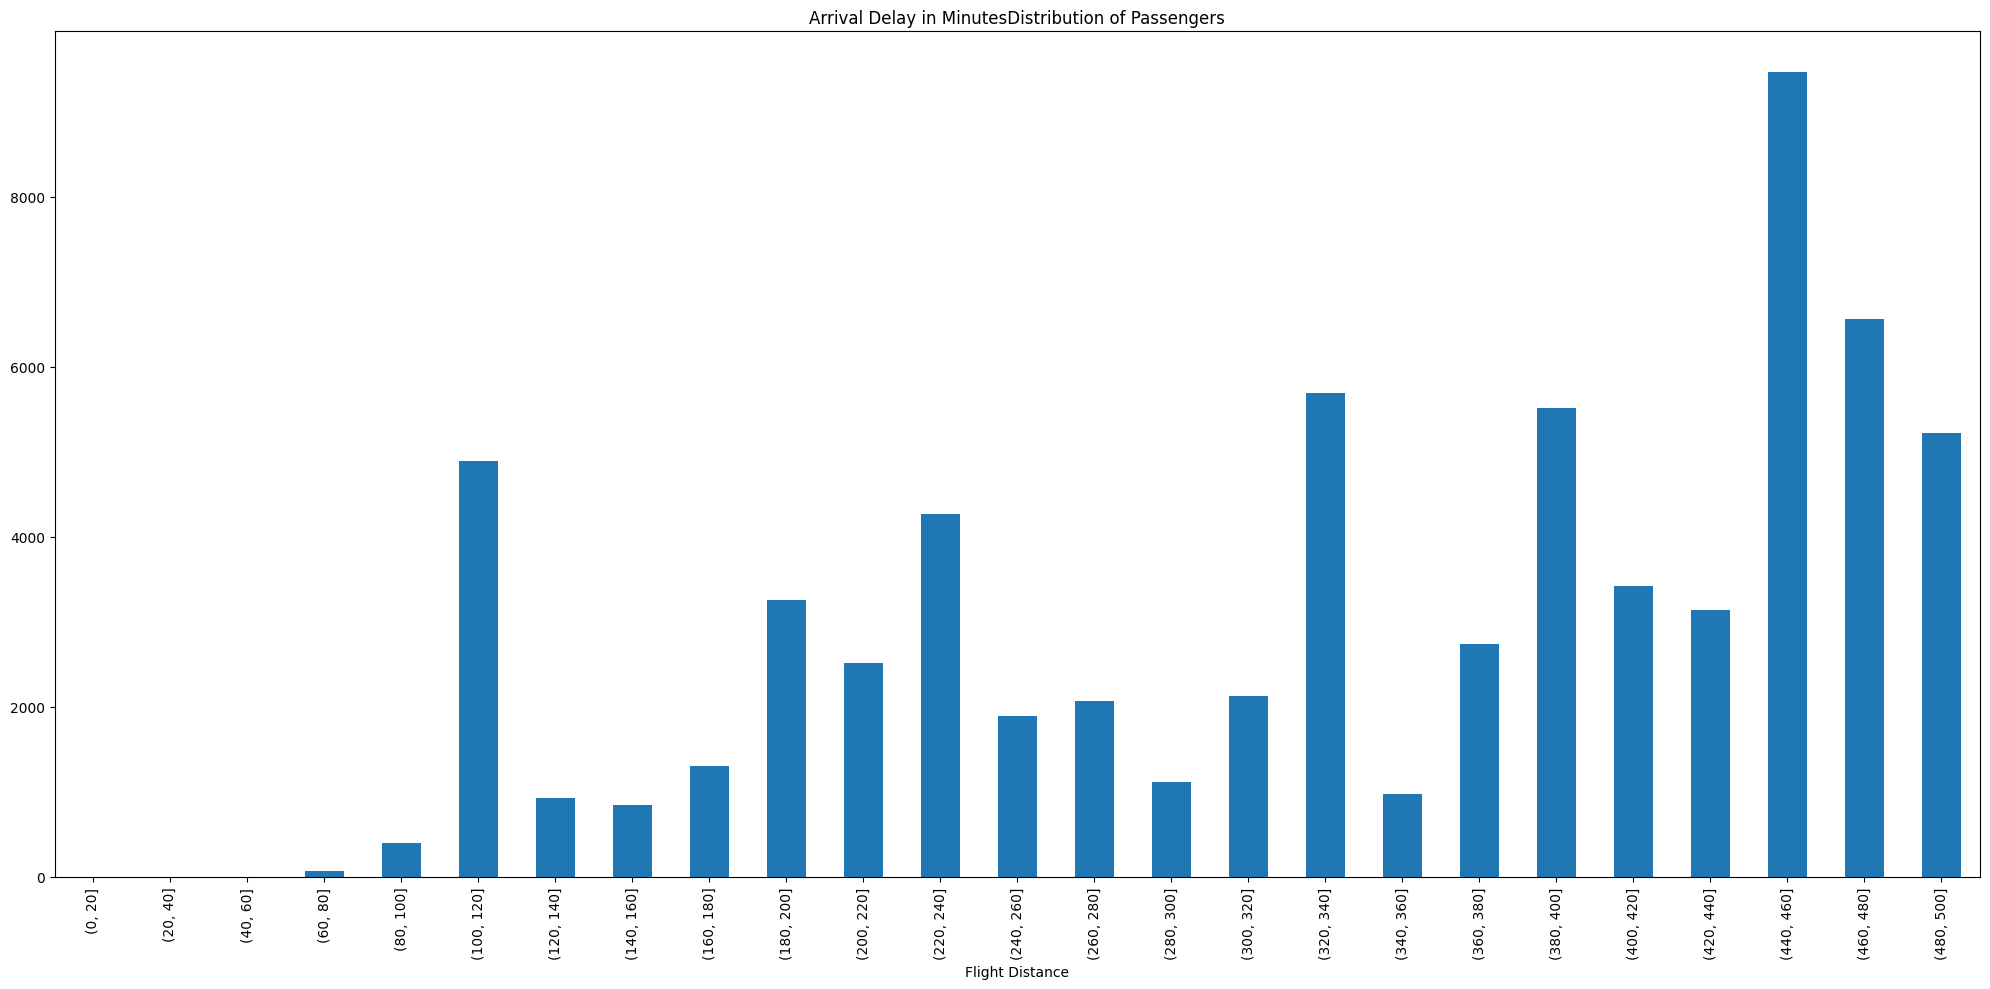

In [11]:
for _,col in data[['Departure Delay in Minutes','Arrival Delay in Minutes']].items():
    plt.figure(figsize=(20,10))
    bins=np.arange(0,520,20)
    distance_distribution=pd.cut(col,bins=bins)
    pd.cut(flight_distance_distribution,bins=bins).value_counts().sort_index().plot(kind='bar')
    plt.title(col.name+'Distribution of Passengers')
    plt.tight_layout()
    plt.show()

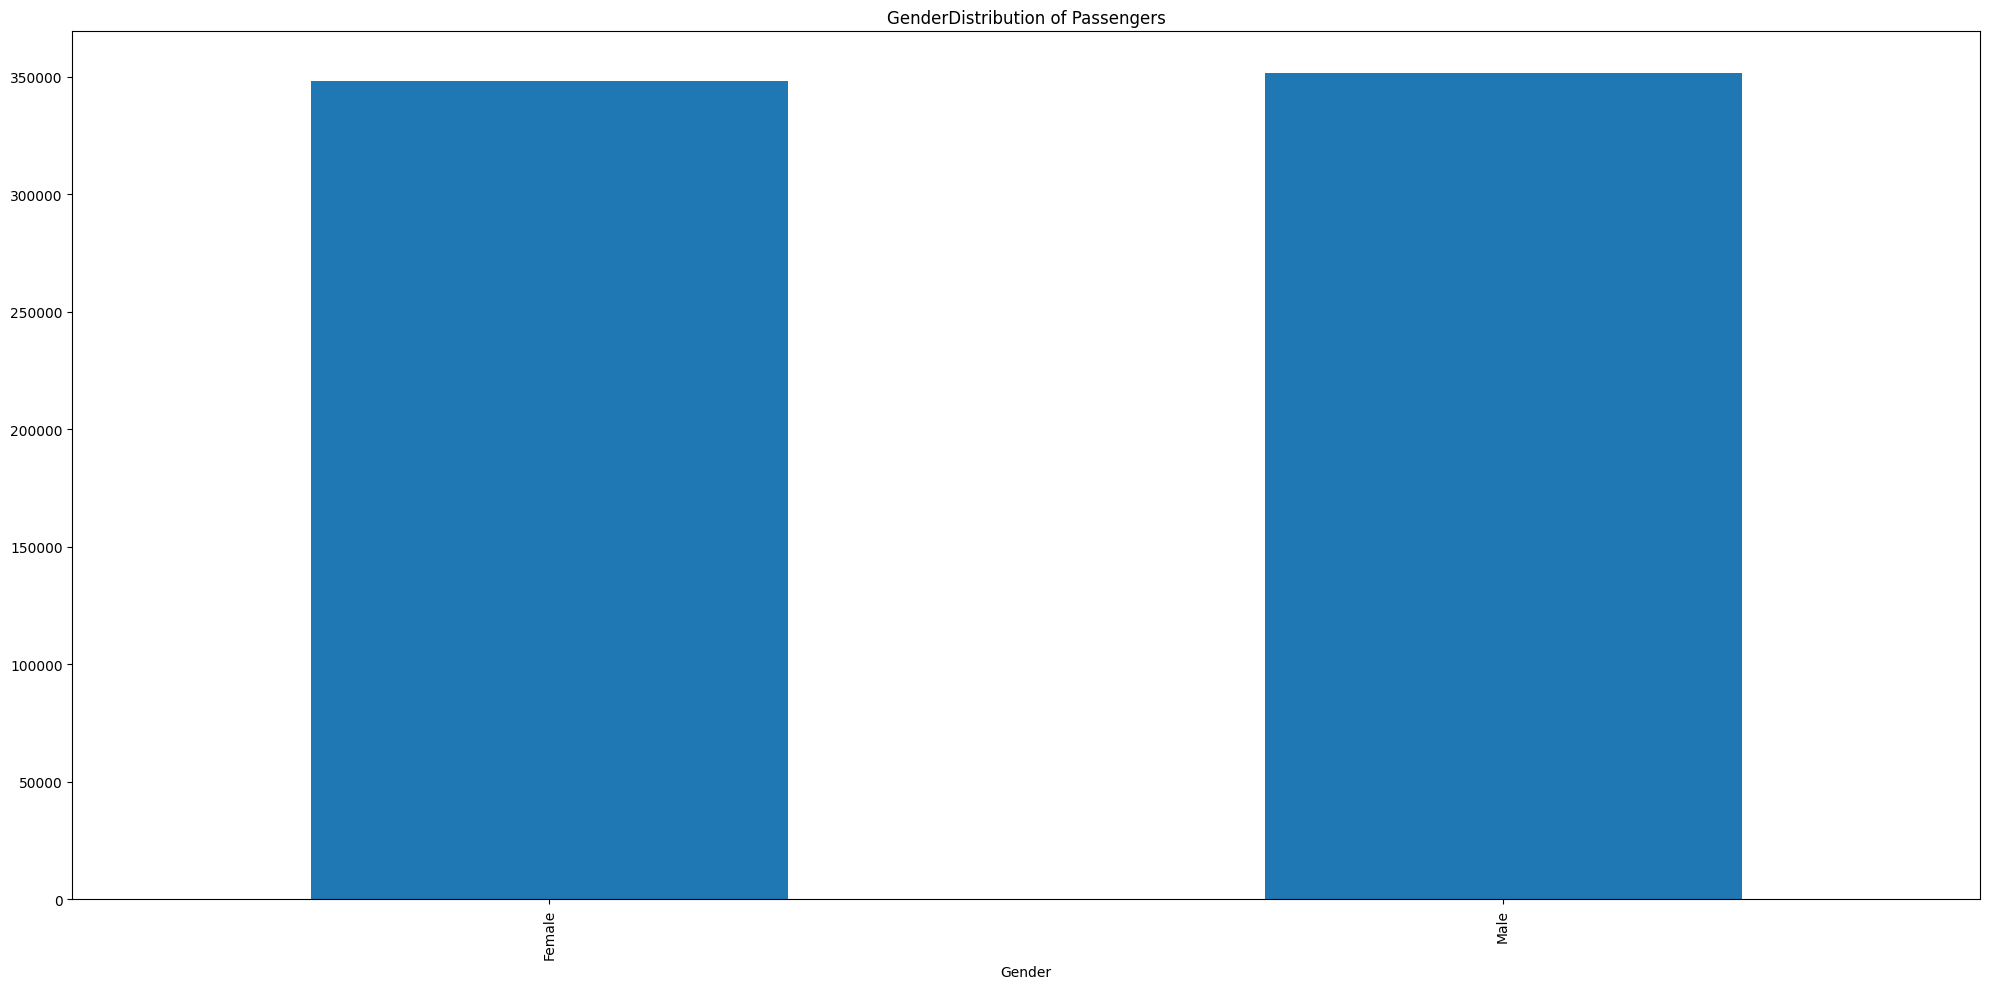

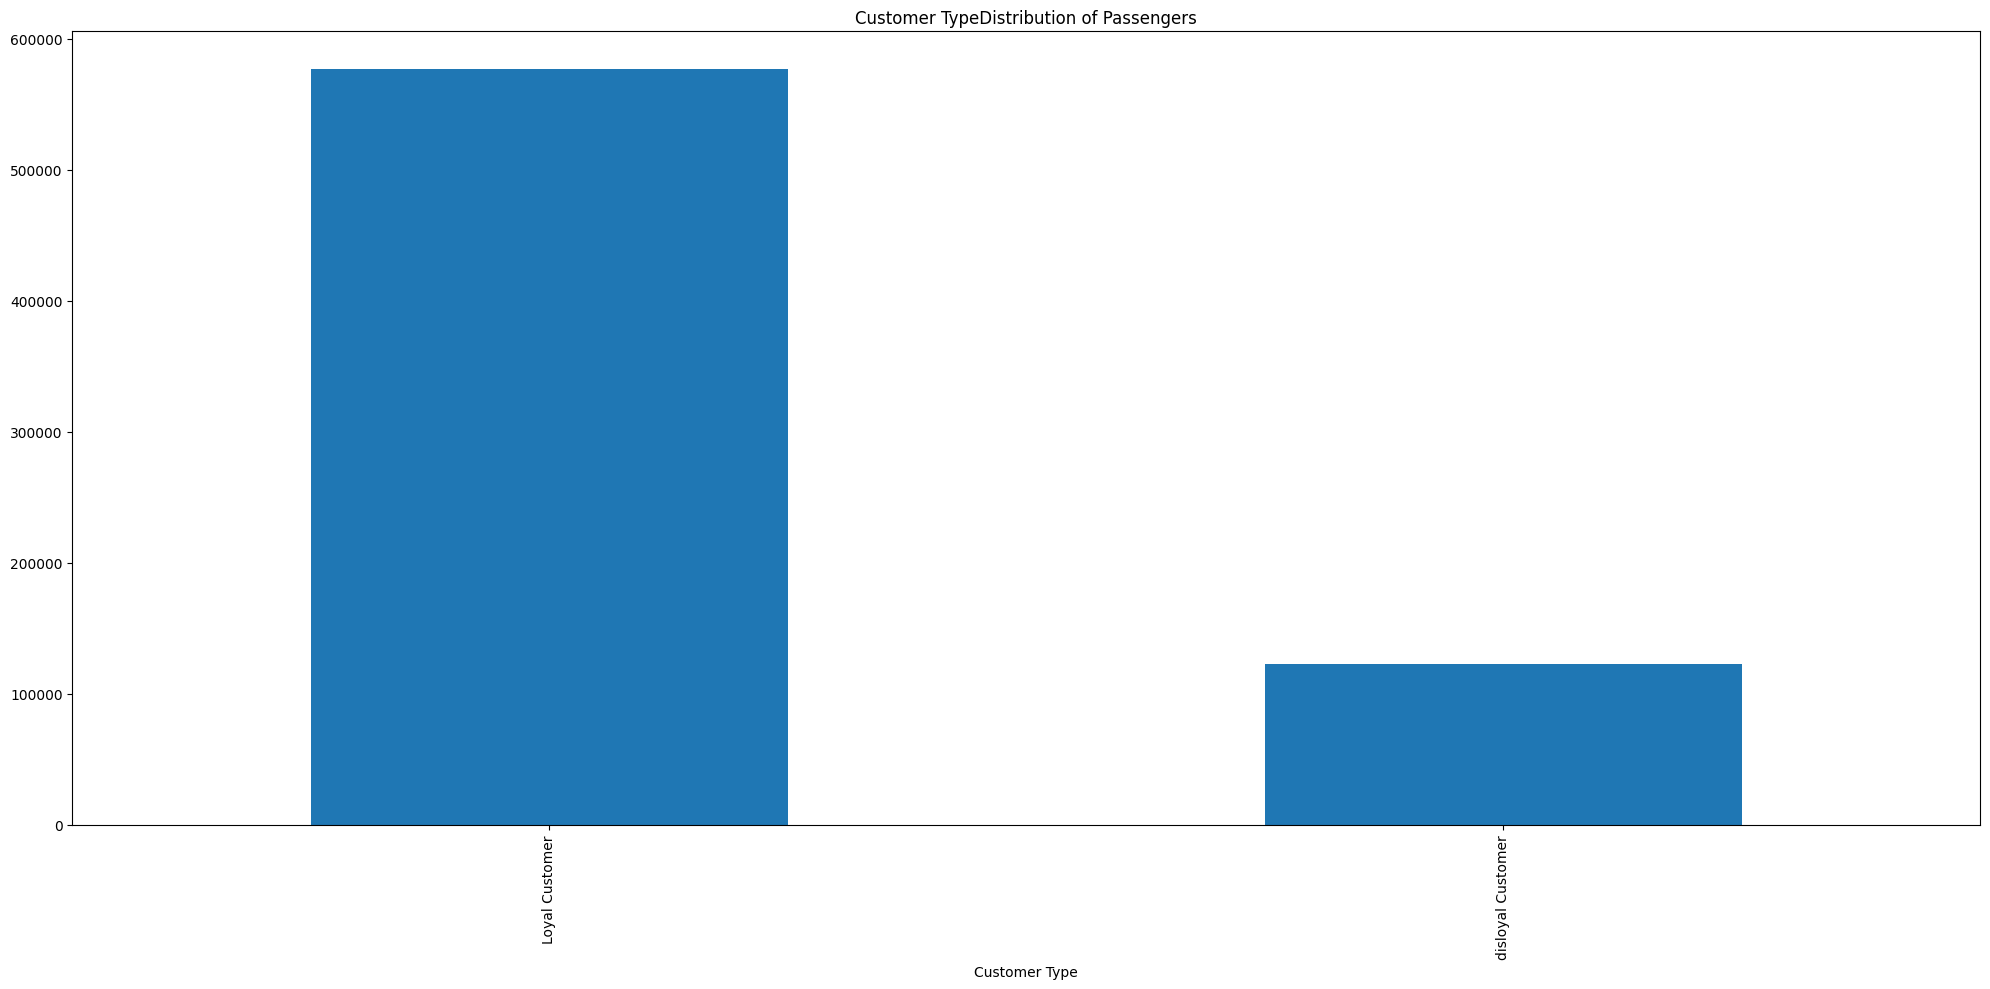

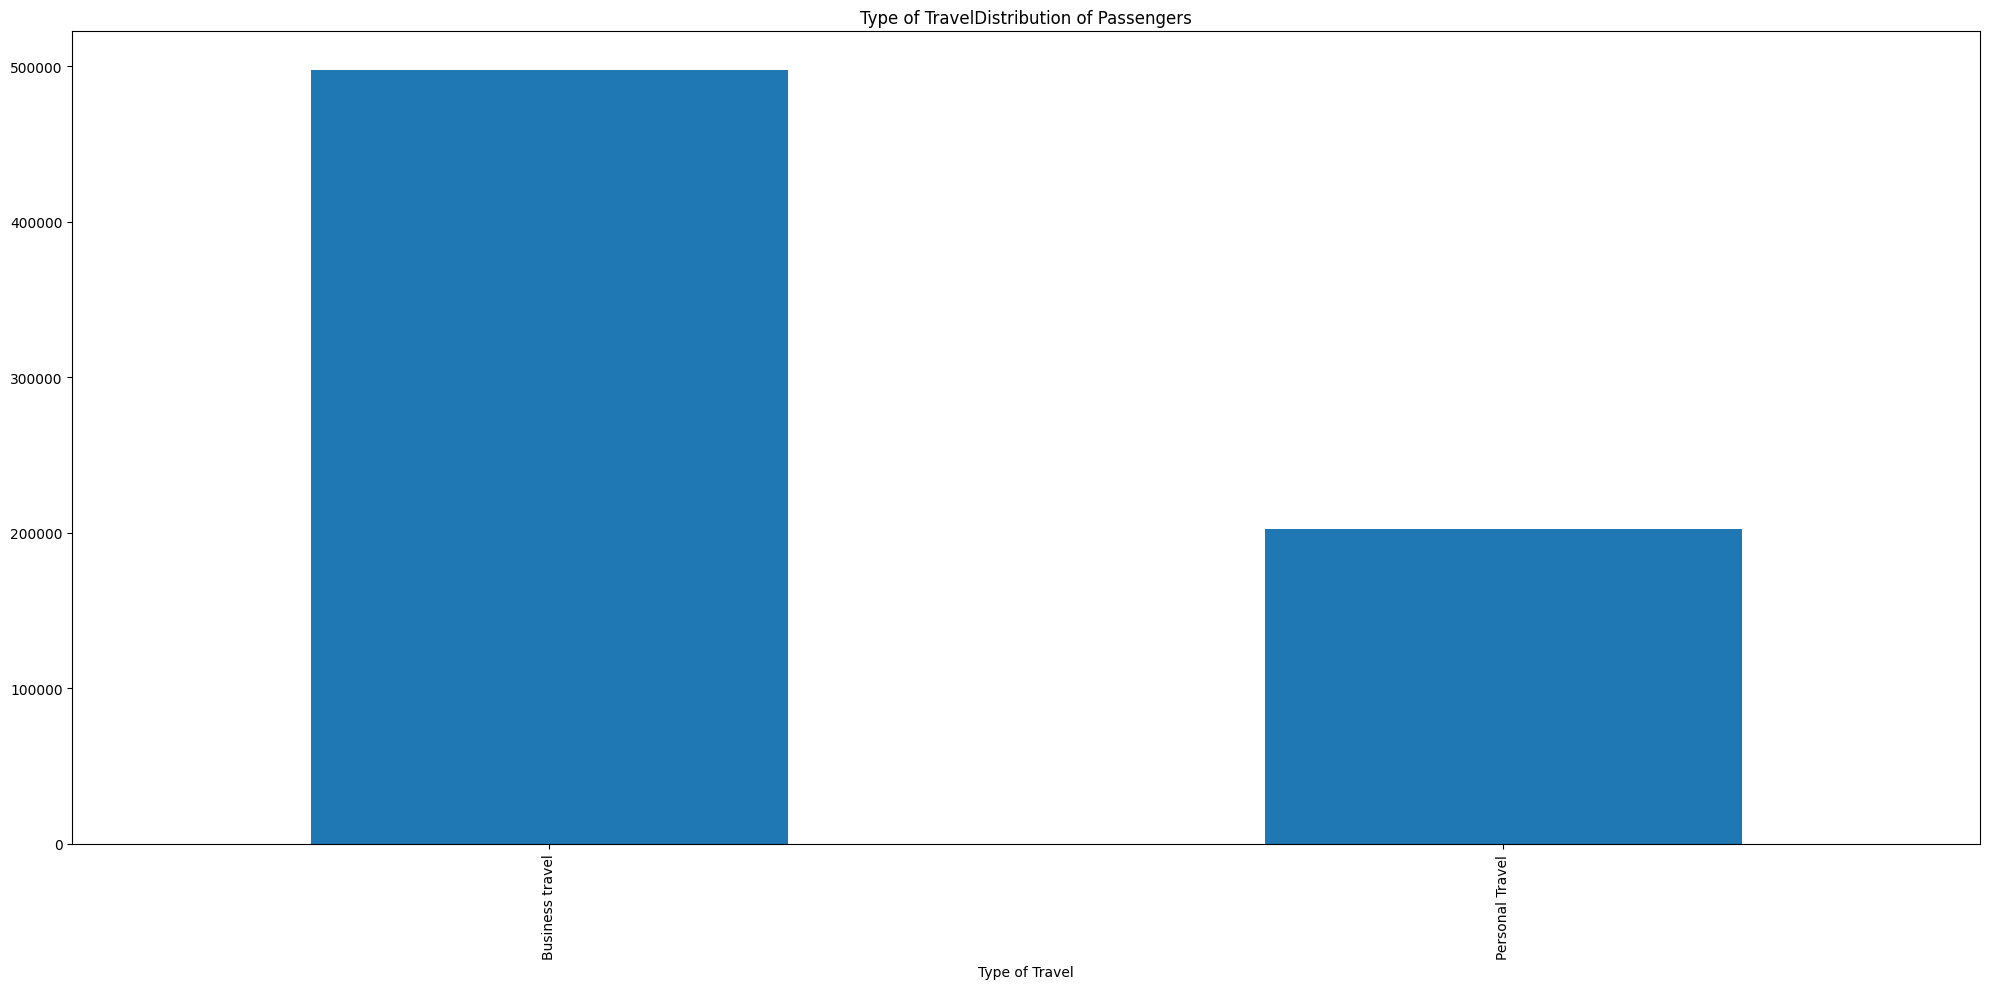

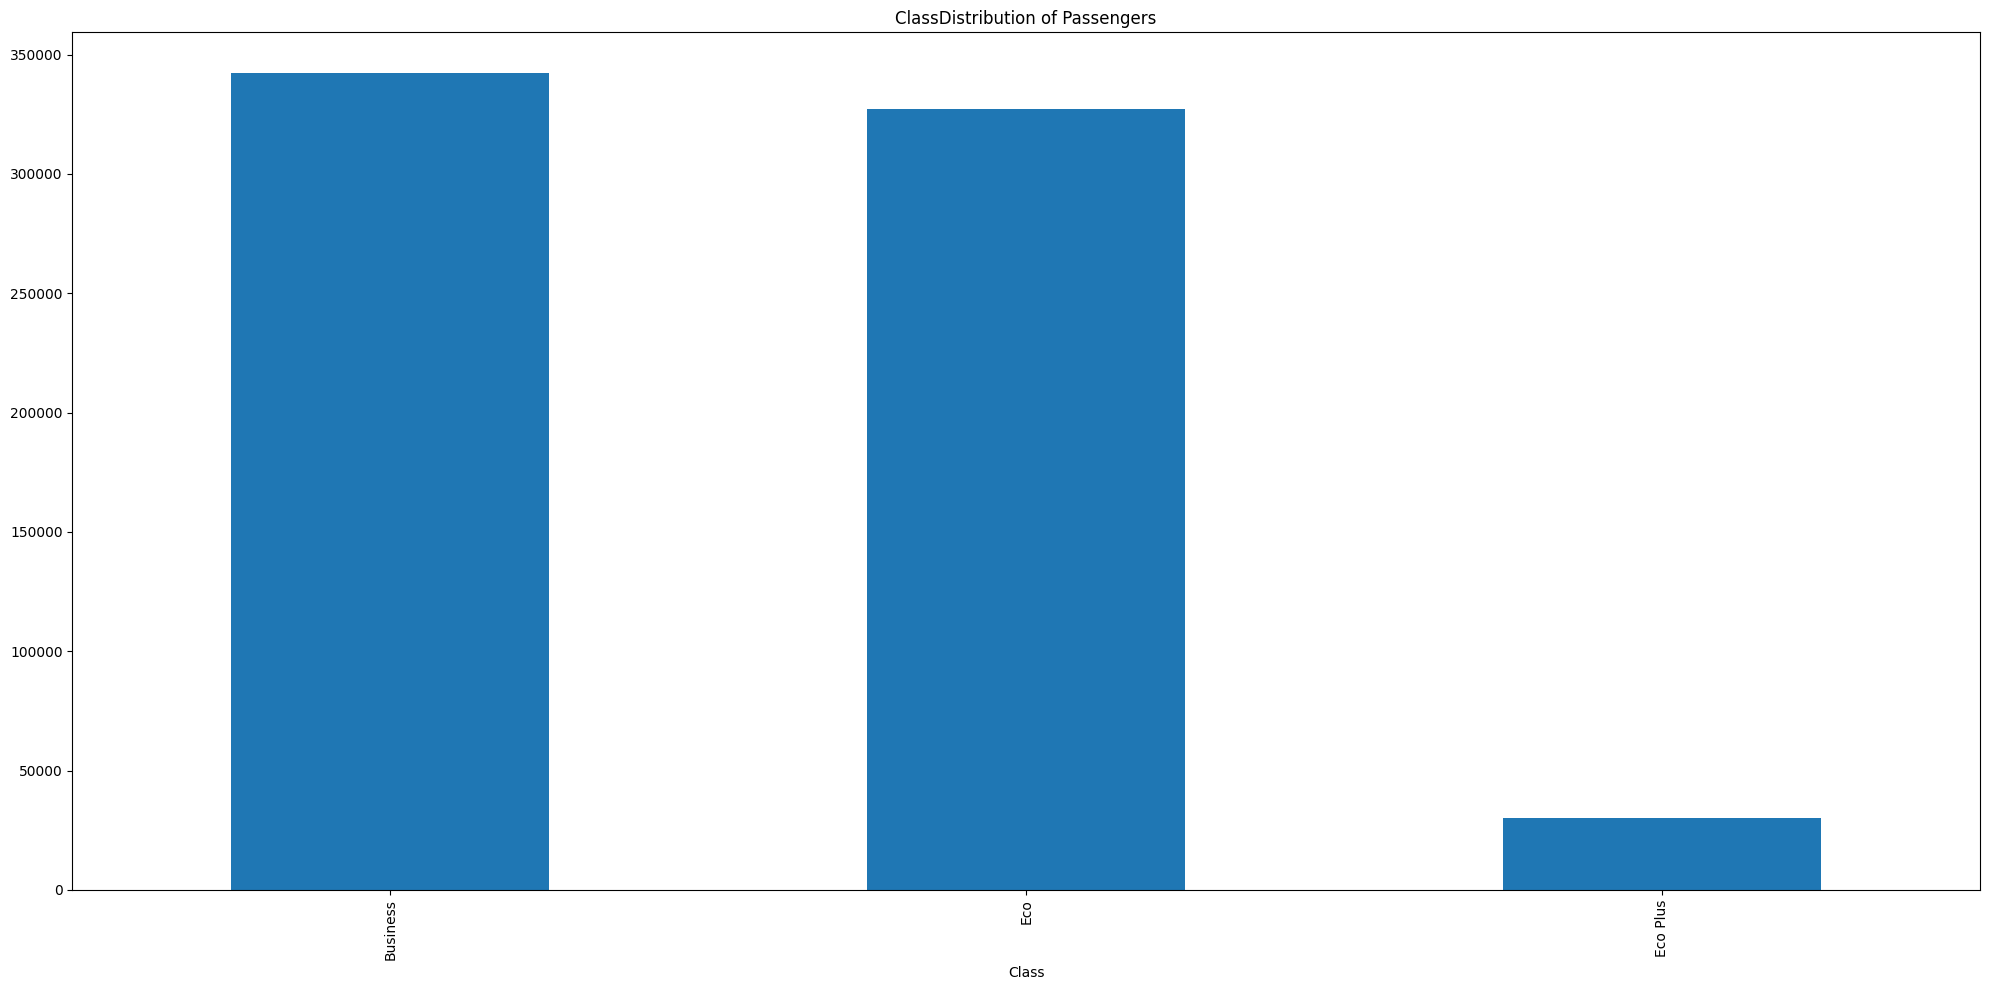

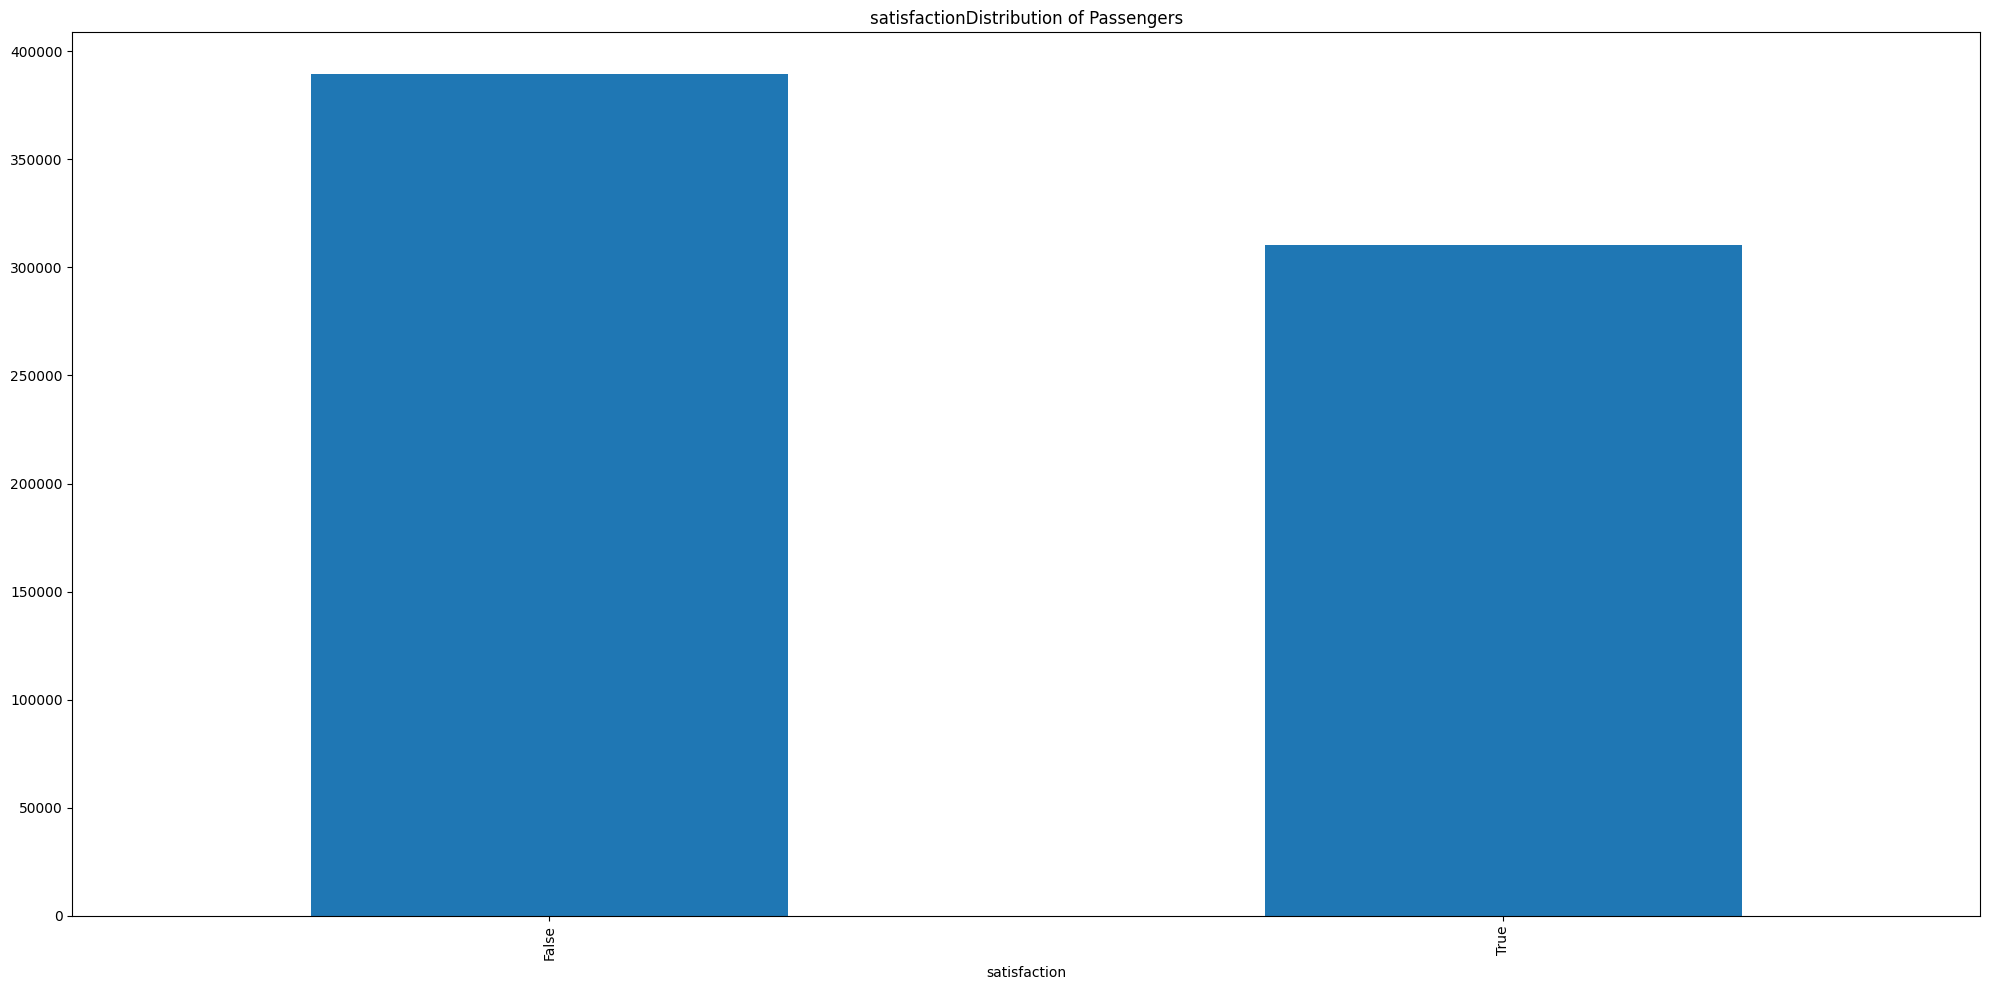

In [12]:
for _,col in data[['Gender',      'Customer Type',   'Type of Travel',     'Class',  'satisfaction']].items():
    plt.figure(figsize=(20,10))
    col.value_counts().sort_index().plot(kind='bar')
    plt.title(col.name+'Distribution of Passengers')
    plt.tight_layout()
    plt.show()